# Дипломски рад

**Аутор:** Тијана Ђоковић

Анализа фактора који се односе на опредељење за СТЕМ смер у средњој школи (упитник, подаци у `STEM.xlsx`). У наставку: припрема података, дефиниција циљне променљиве, описна анализа и основни статистички тестови.

# 1. Припрема података

## 1.1. Учитавање и преглед скупа података

Учитавамо одговоре из Excel фајла (`STEM.xlsx` — без измене из кода), користимо **pandas** за табеларне податке, **seaborn/matplotlib** за графике и **scipy.stats** за тестове.

Пре моделовања (ако се додаје касније) вредно је проверити недостајуће вредности, типове колона и да ли текстуални одговори имају неочекиване варијанте (размак, различит писмо).

**Напомена о називима колона:** Након учитавања, у овом notebook-у скраћујемо само називе колона за *најчешћу оцену по предмету*, *занимљивост*, *тежину* и *корисност* предмета (исти текст као у упитнику, скраћен за прегледност). Изворни фајл `STEM.xlsx` се **не мења** — преименовање важи само за `DataFrame` у сећији испод.

In [1]:
import re

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, chi2_contingency

sns.set_style("whitegrid")


In [2]:
df = pd.read_excel("STEM.xlsx")


def _preimenuj_kolone_predmeta(kolone):
    """Скраћени називи колона за предмете (само у овом DataFrame-у; Excel остаје непромењен)."""
    preimenovanja = {}
    obrazac_ocena = re.compile(
        r"^Најчешћа оцена из наведених предмета у основној школи ми је била: (\[.+\])$"
    )
    obrazac_zanimljivost = re.compile(
        r"^Колико ти је поједини предмет био занимљив у основној школи\?\s+(\[.+\])$"
    )
    obrazac_tezina = re.compile(
        r"^Колико ти је поједини предмет био тежак у основној школи\?\s+(\[.+\])$"
    )
    obrazac_korisnost = re.compile(
        r"^Колико ти је поједини предмет био користан у основној школи\?\s+(\[.+\])$"
    )
    for kolona in kolone:
        if not isinstance(kolona, str):
            continue
        m = obrazac_ocena.match(kolona)
        if m:
            preimenovanja[kolona] = f"Најчешћа оцена {m.group(1)}"
            continue
        m = obrazac_zanimljivost.match(kolona)
        if m:
            preimenovanja[kolona] = f"Занимљив {m.group(1)}"
            continue
        m = obrazac_tezina.match(kolona)
        if m:
            preimenovanja[kolona] = f"Тежак {m.group(1)}"
            continue
        m = obrazac_korisnost.match(kolona)
        if m:
            preimenovanja[kolona] = f"Корисан {m.group(1)}"
            continue
    return preimenovanja


df.rename(columns=_preimenuj_kolone_predmeta(df.columns), inplace=True)
df.head()

,Timestamp,Пол:,Година рођења:,Похађам средњу школу:,Смер:,Разред:,Одрастао/ла сам у:,Основну школу сам завршио/ла у:,Занимање твоје мајке:,Стручна спрема твоје мајке:,...,Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Вршњаци],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Наставник],"Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Медији (телевизија, друштвене мреже, интернет, блогови итд)]",Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Склоност ка одређеној групи предмета],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Добра проходност на факултет који желим да студирам по завршетку средње школе],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Интересовање за занимање којим желим да се бавим у будућности],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Школски психолог/педагог],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Разредни старешина],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Предметни наставник],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Неко друго стручно лице]
0,2023-11-28 21:50:20.078,мушки,2007,„Јован Јовановић Змај“ Нови Сад,специјализовано одељење за ученике са посебним...,2.0,већем граду,већем граду,preduzetnica,завршен факултет,...,1 - нимало,2 - мало,3 - средње,5 - изразито,5 - изразито,5 - изразито,1 - нимало,1 - нимало,1 - нимало,1 - нимало
1,2023-11-28 21:52:10.331,женски,2005,„Јован Јовановић Змај“ Нови Сад,природно-математички,4.0,варошици,варошици,Radnik,завршена виша школа,...,1 - нимало,4 - доста,4 - доста,5 - изразито,5 - изразито,4 - доста,1 - нимало,2 - мало,4 - доста,1 - нимало
2,2023-11-28 21:52:16.136,женски,2005,„Јован Јовановић Змај“ Нови Сад,специјализовано одељење за ученике са посебним...,4.0,већем граду,већем граду,Lekar,завршен факултет,...,1 - нимало,1 - нимало,1 - нимало,2 - мало,4 - доста,1 - нимало,1 - нимало,1 - нимало,1 - нимало,1 - нимало
3,2023-11-28 21:52:17.193,женски,2007,„Јован Јовановић Змај“ Нови Сад,билингвално одељење (одељење у коме се део нас...,3.0,већем граду,већем граду,Diplomirani ekonomista,завршен факултет,...,3 - средње,4 - доста,2 - мало,5 - изразито,3 - средње,1 - нимало,5 - изразито,2 - мало,3 - средње,1 - нимало
4,2023-11-28 21:52:41.167,женски,2008,„Јован Јовановић Змај“ Нови Сад,природно-математички,1.0,селу,селу,Ekonomista,завршен факултет,...,1 - нимало,3 - средње,1 - нимало,3 - средње,4 - доста,4 - доста,4 - доста,5 - изразито,4 - доста,4 - доста


**Закључак:** подаци су учитани исправно — првих неколико редова показује очекивану структуру упитника. Скраћивање назива колона (Најчешћа оцена / Занимљив / Тежак / Корисан + [предмет]) успешно је примењено само у овом `DataFrame`-у; изворни `STEM.xlsx` остаје непромењен.

## 1.2. Основне информације о скупу података

`info()` приказује типове и недостајуће вредности по колони; `describe()` сажетак за нумеричке колоне; `shape` број редова и колона.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Columns: 105 entries, Timestamp to Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Неко друго стручно лице]
dtypes: datetime64[ns](1), float64(1), int64(15), object(88)
memory usage: 856.5+ KB


In [4]:
df.describe()

,Timestamp,Година рођења:,Разред:,Најчешћа оцена [Српски језик и књижевност],Најчешћа оцена [Енглески језик],Најчешћа оцена [2. страни језик],Најчешћа оцена [Историја],Најчешћа оцена [Географија],Најчешћа оцена [Биологија],Најчешћа оцена [Математика],Најчешћа оцена [Информатика],Најчешћа оцена [Физика],Најчешћа оцена [Хемија],Најчешћа оцена [Музичка култура],Најчешћа оцена [Ликовна култура],Најчешћа оцена [Физичко васпитање],Најчешћа оцена [Техника и технологија]
count,1044,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000
mean,2023-12-19 18:51:07.355917568,2006.895594,2.381322,4.766284,4.796935,4.800766,4.818008,4.819923,4.802682,4.546935,4.909004,4.585249,4.598659,4.954023,4.954981,4.966475,4.909004
min,2023-11-28 21:50:20.078000,2005.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2023-11-29 21:27:34.893999872,2006.000000,1.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.000000,5.000000,4.000000,4.000000,5.000000,5.000000,5.000000,5.000000
50%,2023-12-14 09:02:53.044000,2007.000000,2.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
75%,2023-12-18 10:52:50.224750080,2008.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
max,2024-05-19 13:14:19.370000,2011.000000,8.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
std,NaN,1.211807,1.282004,0.549534,0.563299,0.556113,0.541137,0.554028,0.555071,0.824307,0.408861,0.771877,0.776475,0.333196,0.328984,0.306257,0.418136


In [5]:
print('Димензије:', df.shape)

Димензије: (1044, 105)


**Закључак:** скуп података има 1044 реда и 105 колона. Типови колона (`df.info()`) показују очекивану мешавину — временски печат (Timestamp), нумеричке колоне (оцене, година рођења, разред) и претежно текстуалне (object) категоријске и Ликерт колоне. `describe()` за нумеричке колоне показује да су просечне најчешће оцене високе (углавном између 4.5 и 5.0), што детаљније анализирамо у наставку рада.

### 1.1.1. Провера недостајућих вредности

Проверавамо број недостајућих (`NaN`) вредности по колони, како је најављено на почетку одељка 1.1.

In [6]:
missing_counts = df.isna().sum()
missing_cols = missing_counts[missing_counts > 0]

if len(missing_cols) == 0:
    print("Нема недостајућих вредности ни у једној од", df.shape[1], "колона.")
else:
    print(f"Број колона са недостајућим вредностима: {len(missing_cols)}")
    print(missing_cols)

Нема недостајућих вредности ни у једној од 105 колона.


**Закључак:** скуп података нема ниједну недостајућу вредност (1044 реда × 105 колона, потпуно попуњено). Није било потребе за импутацијом или изостављањем редова/колона по овом основу.

### 1.1.2. Провера неочекиваних текстуалних варијанти

Проверавамо да ли текстуалне (object) колоне садрже вишак размака на крајевима или мешано писмо (ћирилица и латиница у истом одговору), како је најављено на почетку одељка 1.1.

In [7]:
def _ima_razmak(x):
    return isinstance(x, str) and x != x.strip()


def _ima_mesano_pismo(x):
    if not isinstance(x, str):
        return False
    cirilica = bool(re.search('[Ѐ-ӿ]', x))
    latinica = bool(re.search('[A-Za-z]', x))
    return cirilica and latinica


tekstualne_kolone = df.select_dtypes(include='object').columns
print(f"Број текстуалних (object) колона: {len(tekstualne_kolone)}")

kolone_sa_varijantama = {}
for col in tekstualne_kolone:
    vrednosti = df[col].dropna().unique()
    razmak = [v for v in vrednosti if _ima_razmak(v)]
    mesano = [v for v in vrednosti if _ima_mesano_pismo(v)]
    if razmak or mesano:
        kolone_sa_varijantama[col] = {'вишак размака': len(razmak), 'мешано писмо': len(mesano)}

print(f"\nБрој колона са неочекиваним варијантама: {len(kolone_sa_varijantama)}")
for col, broj in kolone_sa_varijantama.items():
    print(f"  {col}: {broj}")

Број текстуалних (object) колона: 88

Број колона са неочекиваним варијантама: 4
  Занимање твоје мајке:: {'вишак размака': 92, 'мешано писмо': 1}
  Занимање твог оца:: {'вишак размака': 82, 'мешано писмо': 0}
  Зашто сте изабрали да упишите Гимназију?: {'вишак размака': 139, 'мешано писмо': 0}
  Зашто сте изабрали да упишете овај смер?: {'вишак размака': 133, 'мешано писмо': 1}


**Закључак:** неочекиване варијанте (вишак размака, мешано писмо) постоје искључиво у четири слободнотекстуалне колоне — `Занимање твоје мајке:`, `Занимање твог оца:`, `Зашто сте изабрали да упишите Гимназију?` и `Зашто сте изабрали да упишете овај смер?`. Ниједна од ових колона се не користи у даљој анализи (већ су искључене из `X` у одељку 1.4 као описне/слободнотекстуалне), тако да ове варијанте немају утицаја на резултате. Ниједна друга (категоријска или Ликерт) колона нема оваквих варијанти.

## 1.3. Провера квалитета: `Разред:`

Колона `Разред:` треба да садржи цео број (типично 1–4 за гимназију; више вредности могуће за специјализована одељења у оквиру осмогодишњих програма). Проверавамо да ли постоје нецелобројне вредности и, ако постоје, заокружујемо их на најближи цео број.

In [8]:
neispravni_razred = df[df['Разред:'] % 1 != 0]
print(f"Број редова са нецелобројном вредношћу у 'Разред:': {len(neispravni_razred)}")
print(neispravni_razred[['Разред:']])

df.loc[neispravni_razred.index, 'Разред:'] = df.loc[neispravni_razred.index, 'Разред:'].round()

print("\nВредност заокружена на најближи цео број. Расподела после исправке:")
print(df['Разред:'].value_counts().sort_index())

Број редова са нецелобројном вредношћу у 'Разред:': 1
     Разред:
775      2.1

Вредност заокружена на најближи цео број. Расподела после исправке:
Разред:
1.0    344
2.0    235
3.0    237
4.0    214
6.0      1
7.0      5
8.0      8
Name: count, dtype: int64


**Закључак:** пронађен је тачно један ред (индекс 775) са нецелобројном вредношћу `Разред: 2.1`, заокружен на најближи цео број (2). После исправке, расподела разреда је: 1 (344), 2 (235), 3 (237), 4 (214) редова, док преостали ретки редови ван опсега 1–4 (6, 7, 8) детаљно се разматрају у наредном одељку.

### 1.3.1. Провера доследности: разреди ван опсега 1–4 и година рођења

Претпостављамо да свака школа у скупу података омогућава упис ученика директно у **7. или 8. разред** (рана/специјализована одељења за надарене ученике), поред стандардних разреда 1–4. Разреди **5 и 6** не постоје ни у једном програму.

За све редове ван опсега 1–4 (без обзира на школу) проверавамо:
1. да ли је вредност разреда 7 или 8 (дозвољено) — све остало (нпр. 5, 6) је аномалија;
2. да ли се година рођења слаже са очекиваном годином рођења за тај разред (претпоставка: почетак школовања око 7. године живота; референтна школска 2023/2024. година).

In [9]:
REFERENTNA_GODINA = 2023

van_opsega = df[~df['Разред:'].isin([1, 2, 3, 4])].copy()
van_opsega['Дозвољен разред (7 или 8)'] = van_opsega['Разред:'].isin([7, 8])
van_opsega['Очекивана година рођења'] = REFERENTNA_GODINA - (van_opsega['Разред:'] + 6)
van_opsega['Одступање (год.)'] = (
    van_opsega['Година рођења:'] - van_opsega['Очекивана година рођења']
).abs()

print(van_opsega[[
    'Похађам средњу школу:', 'Разред:', 'Дозвољен разред (7 или 8)',
    'Година рођења:', 'Очекивана година рођења', 'Одступање (год.)'
]].to_string())

anomalije = van_opsega[~van_opsega['Дозвољен разред (7 или 8)'] | (van_opsega['Одступање (год.)'] > 2)]
print(f"\nБрој потврђених аномалија: {len(anomalije)}")
print(anomalije[['Похађам средњу школу:', 'Разред:', 'Година рођења:']])

               Похађам средњу школу:  Разред:  Дозвољен разред (7 или 8)  Година рођења:  Очекивана година рођења  Одступање (год.)
6    „Јован Јовановић Змај“ Нови Сад      8.0                       True            2010                   2009.0               1.0
11   „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
17   „Јован Јовановић Змај“ Нови Сад      7.0                       True            2010                   2010.0               0.0
55   „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
115  „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
117  „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
118  „Јован Јовановић Змај“ Нови Сад      7.0                       True    

**Закључак:** провера проналази тачно једну потврђену аномалију — ученик/ца Друге крагујевачке гимназије са `Разред: 6` и `Година рођења: 2005` (ни разред није у дозвољеном скупу {1,2,3,4,7,8}, нити година рођења одговара очекиваној за тај разред — одступање 6 година). Сви остали редови ван опсега 1–4 показују доследан образац (разред и година рођења се слажу за 7./8. разред).

Ову вредност **намерно остављамо непромењену** у `df`: ни `Разред:` ни `Година рођења:` не улазе у дефиницију циљне променљиве `STEM` (која зависи искључиво од `Смер:`), нити се користе у било ком од статистичких тестова или корелационе матрице у наставку — тако да ова аномалија нема утицаја на резултате анализе. Пошто је реч о само једном реду од 1044, задржавамо га уз ову напомену уместо да га бришемо или коригујемо.

## 1.4. Дефинисање циљне променљиве (STEM vs NON-STEM)

Циљна променљива је **бинарна**: ученик је на једном од наведених *СТЕМ* смерава у гимназији (`1`) или није (`0`). Вредност градимо из колоне **`Смер:`** (како је у анкети), без измене изворног Excel фајла.

Листа `stem_smerovi` треба да одговара дефиницији СТЕМ-а у тексту рада; ако се дефиниција промени, мења се само ова листа и поново покрећу ћелије испод.


Пре дефинисања листе `stem_smerovi`, прегледамо све различите вредности колоне `Смер:` и њихове фреквенције — тако имамо потпун преглед свих смерова који се јављају у подацима, пре него што одлучимо који од њих улазе у СТЕМ дефиницију.

In [10]:
df['Смер:'].value_counts(dropna=False)

Смер:
општи смер                                                                            464
природно-математички                                                                  222
специјализовано одељење за ученике са посебним способностима за информатику            84
специјализовано одељење за ученике са посебним способностима за математику             62
специјализовано одељење за ученике са посебним способностима за биологију и хемију     55
билингвално одељење (одељење у коме се део наставе реализује на страном језику)        55
друштвено-језички                                                                      48
специјализовано одељење за ученике са посебним способностима за филолошке науке        29
специјализовано одељење за ученике са посебним способностима за спорт                  14
специјализовано одељење за ученике са посебним способностима за физику                 11
Name: count, dtype: int64

На основу прегледа свих 10 различитих вредности колоне `Смер:`, као СТЕМ вредности користићемо само следећих пет:

- `природно-математички`
- `специјализовано одељење за ученике са посебним способностима за информатику`
- `специјализовано одељење за ученике са посебним способностима за математику`
- `специјализовано одељење за ученике са посебним способностима за биологију и хемију`
- `специјализовано одељење за ученике са посебним способностима за физику`

Остале вредности (општи смер, билингвално одељење, друштвено-језички, филолошке науке, спорт) третирамо као не-СТЕМ.

In [11]:
stem_smerovi = [
    'природно-математички',
    'специјализовано одељење за ученике са посебним способностима за информатику',
    'специјализовано одељење за ученике са посебним способностима за математику',
    'специјализовано одељење за ученике са посебним способностима за биологију и хемију',
    'специјализовано одељење за ученике са посебним способностима за физику',
]

# Колона STEM: 1 = смер из листе изнад, 0 = остали смерави; NaN у Смер: третирамо као 0
df['STEM'] = df['Смер:'].apply(lambda x: 1 if pd.notna(x) and x in stem_smerovi else 0)

print('Апсолутне фреквенције:')
print(df['STEM'].value_counts().sort_index())
print('\nУдео (нормализовано):')
print(df['STEM'].value_counts(normalize=True).round(4))

# Унапред упозорење ако у подацима има вредности смера које нису у листи (провера конзистентности)
sve_smerove = df['Смер:'].dropna().unique()
nepoznato = [s for s in sorted(sve_smerove, key=str) if s not in stem_smerovi and s is not np.nan]
print(f"\nБрој различитих 'осталих' смерава (није у stem_smerovi): {len(nepoznato)}")

Апсолутне фреквенције:
STEM
0    610
1    434
Name: count, dtype: int64

Удео (нормализовано):
STEM
0    0.5843
1    0.4157
Name: proportion, dtype: float64

Број различитих 'осталих' смерава (није у stem_smerovi): 5


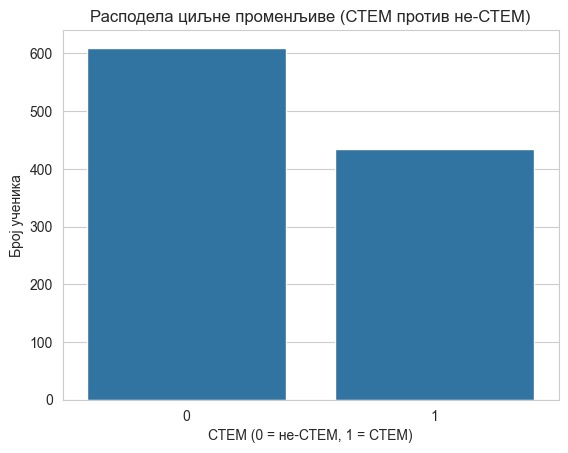

In [12]:
sns.countplot(x='STEM', data=df)
plt.xlabel('СТЕМ (0 = не-СТЕМ, 1 = СТЕМ)')
plt.ylabel('Број ученика')
plt.title('Расподела циљне променљиве (СТЕМ против не-СТЕМ)')
plt.show()

**Закључак:** циљна променљива `STEM` је успешно дефинисана на основу колоне `Смер:` — 434 ученика (41.57%) припада једном од пет наведених СТЕМ смерова, док 610 ученика (58.43%) припада осталим смеровима (не-СТЕМ). Расподела је умерено небалансирана, али без екстремне доминације једне класе, што је прихватљиво за даље статистичко тестирање и моделовање.

### 1.4.1. Искључивање колона за даље моделовање (описни / слободни текст)

Следеће колоне су **описног карактера** (слободан текст или сиров временски печат) и у овом облику нису погодне за директан унос у класичне предиктивне моделе без NLP или додатног кодирања. У наставку их избацујемо из матрице обележја `X`.

- `Timestamp`
- `Занимање твоје мајке:`, `Занимање твог оца:`
- `Зашто сте изабрали да упишите Гимназију?`, `Зашто сте изабрали да упишете овај смер?`

Циљна променљива остаје у `y` (колона `STEM` у `df`).


In [13]:
cols_to_drop = [
    'Timestamp',
    'Занимање твоје мајке:',
    'Занимање твог оца:',
    'Зашто сте изабрали да упишите Гимназију?',
    'Зашто сте изабрали да упишете овај смер?',
]
X = df.drop(columns=cols_to_drop)
y = df['STEM']

print('Колоне у X (укључујући STEM за EDA графике са hue):')
print(X.columns.tolist())

Колоне у X (укључујући STEM за EDA графике са hue):
['Пол:', 'Година рођења:', 'Похађам средњу школу:', 'Смер:', 'Разред:', 'Одрастао/ла сам у:', 'Основну школу сам завршио/ла у:', 'Стручна спрема твоје мајке:', 'Стручна спрема твог оца:', 'Колико има деце у твојој породици, рачунајући и тебе (упиши број):', 'Какав си био/ла ђак у основној школи?', 'Најомиљенији предмет:', 'Други омиљени предмет (омиљени предмет, мање омиљени од претходног):', 'Трећи омиљени предмет (омиљени предмет, мање омиљени од претходна два):', 'Тежак [Српски језик и књижевност]', 'Тежак [Енглески језик]', 'Тежак [2. страни језик]', 'Тежак [Историја]', 'Тежак [Географија]', 'Тежак [Биологија]', 'Тежак [Математика]', 'Тежак [Информатика]', 'Тежак [Физика]', 'Тежак [Хемија]', 'Тежак [Музичка култура]', 'Тежак [Ликовна култура]', 'Тежак [Физичко васпитање]', 'Тежак [Техника и технологија]', 'Корисан [Српски језик и књижевност]', 'Корисан [Енглески језик]', 'Корисан [2. страни језик]', 'Корисан [Историја]', 'Корисан 

In [14]:
# Заједничке ознаке за STEM/не-STEM групу, коришћене у графицима и табелама у наставку
STEM_LABELS = {0: 'НЕ-СТЕМ', 1: 'СТЕМ', 0.0: 'НЕ-СТЕМ', 1.0: 'СТЕМ'}

**Закључак:** уклоњено је пет описних/слободнотекстуалних колона (`Timestamp` и четири колоне са слободним текстом) из матрице обележја `X`, која сада има 101 колону (укључујући циљну променљиву `STEM`, задржану овде ради EDA графика у наредном поглављу). Ове колоне остају недирнуте у `df` и биће поново размотрене, заједно са додатним административним колонама, у одељку 4.1.

# 2. Описна анализа

## 2.1. Анализа неких предмета који припадају СТЕМ областима

Поређење расподеле најчешћих оцена из математике, физике и (као референца) српског језика. Кутијасти дијаграм показује медијан, квартиле и изласке.

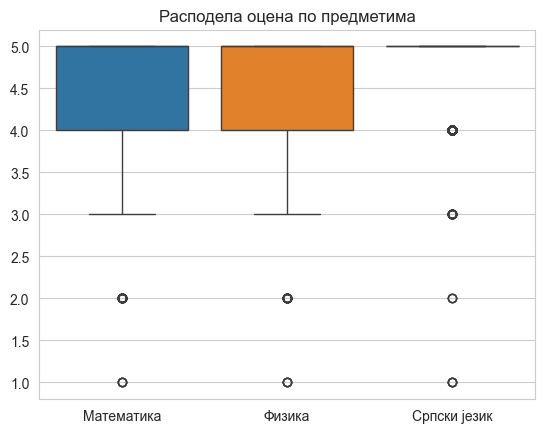

In [15]:
data = X[[
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Српски језик и књижевност]',
]]

sns.boxplot(data=data)

plt.xticks(
    ticks=[0, 1, 2],
    labels=['Математика', 'Физика', 'Српски језик']
)

plt.title('Расподела оцена по предметима')
plt.show()

**Закључак:** медијана оцене је 5 за сва три предмета (види `describe()` из одељка 1.2), али распон је шири код математике и физике — доња граница (25. перцентил) им је 4, за разлику од српског језика где је и доња граница већ 5. То се слаже и са већим стандардним девијацијама за математику (≈0.82) и физику (≈0.77) у односу на српски (≈0.55): оцене из математике и физике варирају више међу ученицима, док су оцене из српског готово увек максималне.

## 2.2. Анализа категоријских обележја

Фреквенције и графикони за изабране категоријске променљиве (нпр. пол, величина места одрастања).

In [16]:
X['Пол:'].value_counts()

Пол:
женски    715
мушки     329
Name: count, dtype: int64

In [17]:
X['Одрастао/ла сам у:'].value_counts()

Одрастао/ла сам у:
већем граду    712
селу           139
мањем граду     98
варошици        95
Name: count, dtype: int64

**Закључак:** узорак је родно небалансиран — 715 ученица (68.5%) наспрам 329 ученика (31.5%). По месту одрастања, знатна већина (712, односно 68.2%) одрасла је у већем граду, док су село (139, 13.3%), мањи град (98, 9.4%) и варошица (95, 9.1%) знатно мање заступљени. Ова структура узорка треба да се има у виду приликом тумачења каснијих резултата — узорак није равномерно распоређен ни по полу ни по степену урбанизације места одрастања.

## 2.3. Однос категоријских обележја и СТЕМ опредељења

Упоредни приказ (hue = STEM) помаже да се види да ли се расподела категорије разликује између СТЕМ и не-СТЕМ групе.

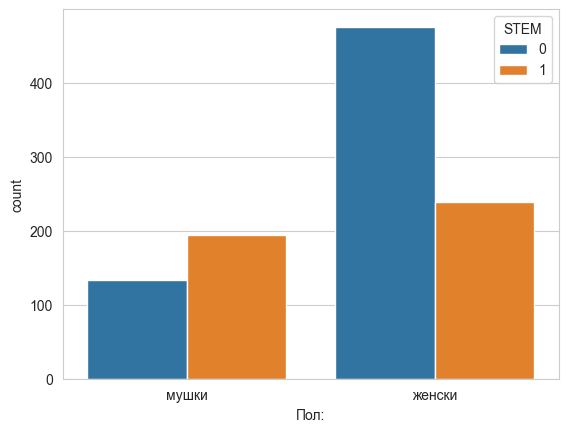

In [18]:
sns.countplot(x='Пол:', hue='STEM', data=X)
plt.show()

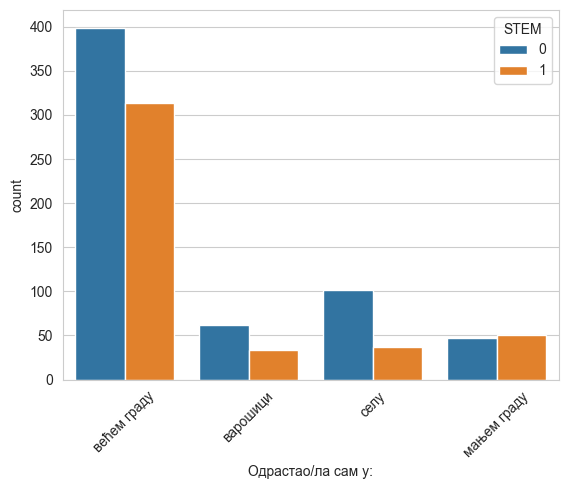

In [19]:
sns.countplot(x='Одрастао/ла сам у:', hue='STEM', data=X)
plt.xticks(rotation=45)
plt.show()

**Закључак:** упоредни приказ (hue = STEM) визуелно указује на разлике у СТЕМ опредељењу и по полу и по месту одрастања — међу мушким ученицима СТЕМ се чини пропорционално заступљенијим него међу женским, а међу ученицима из већих градова пропорционално заступљенијим него међу онима из села. Ова запажања се формално тестирају χ² тестовима у одељцима 3.5 и 3.6.

## 2.4. Стубичасти дијаграм (просеци)

Поређење **просечних** најчешћих оцена из математике, физике и српског језика између групе STEM и не-STEM (`groupby` + `plot(kind='bar')`).

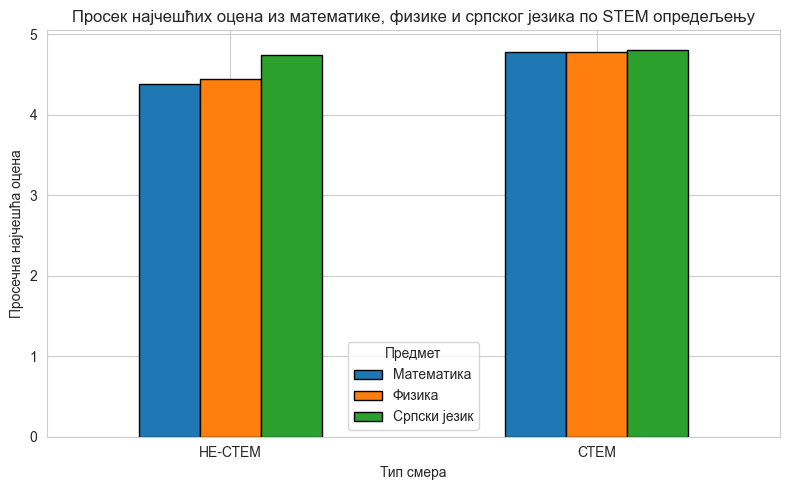

In [20]:
grade_cols_mean = [
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Српски језик и књижевност]',
]
plot_df = X.groupby('STEM')[grade_cols_mean].mean()
plot_df.columns = ['Математика', 'Физика', 'Српски језик']
plot_df.index = [STEM_LABELS.get(k, k) for k in plot_df.index]
ax = plot_df.plot(kind='bar', rot=0, figsize=(8, 5), edgecolor='black')
plt.ylabel('Просечна најчешћа оцена')
plt.xlabel('Тип смера')
plt.title('Просек најчешћих оцена из математике, физике и српског језика по STEM опредељењу')
plt.legend(title='Предмет')
plt.tight_layout()
plt.show()

**Закључак:** стубичасти дијаграм показује да СТЕМ ученици у просеку остварују веће оцене из математике и физике него не-СТЕМ ученици, док су просечне оцене из српског језика визуелно врло сличне за обе групе. Ова разлика за математику и физику формално се потврђује Welch t-тестовима у одељку 3.1.

In [21]:
def _likert_u_broj(x):
    """'1 - нимало' или већ int 1–5 → број за просек."""
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, np.integer)):
        return int(x)
    if isinstance(x, float) and x == int(x):
        return int(x)
    s = str(x).strip()
    if not s:
        return np.nan
    return int(s.split('-')[0].strip())

## 2.5. Корелациона матрица

### 2.5.1. Избор колона за ову матрицу

Користимо само: **STEM**, најчешће оцене из **математике**, **физике** и **информатике**, као и Ликерт процене **занимљивости** и **тежине** за **математику** и **физику** (списак је експлицитно у наредној ћелији).

Ликерт ставови се претварају у бројеве (види ћелију испод); затим се за изабране колоне рачуна **Спирманова (Spearman) корелација ранга**, а не Пирсонова: већина укључених променљивих је **ординална** (Ликерт скале 1–5, оцене), а Спирманова корелација претпоставља само монотону везу међу рангирањем вредности, без претпоставке да су размаци између категорија једнаки (што Пирсонова корелација имплицитно претпоставља). За STEM (бинарна) насупрот осталим, Спирманова корелација и даље даје валидну меру повезаности. Матрица је илустративна — за закључке о узрочности потребна је додатна анализа.

Питања са одговорима у облику *„1 - нимало“*, *„2 - мало“*, … мапирамо на цео број (1–5) преузимањем дела пре цртице (помоћу `_likert_u_broj` дефинисане изнад). То омогућава корелацију и топлотну мапу; **није** исто што и формално моделирање као континуиране променљиве, али је уобичајен корак у описној анализи.

In [22]:
likert_cols = [
    col
    for col in X.columns
    if 'Процени' in col
    or col.startswith('Занимљив ')
    or col.startswith('Тежак ')
    or col.startswith('Корисан ')
]

for col in likert_cols:
    X[col] = X[col].apply(_likert_u_broj)

In [23]:
selected_columns = [
    'STEM',
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Информатика]',
    'Занимљив [Математика]',
    'Занимљив [Физика]',
    'Тежак [Математика]',
    'Тежак [Физика]',
]

corr = X[selected_columns].corr(method='spearman')

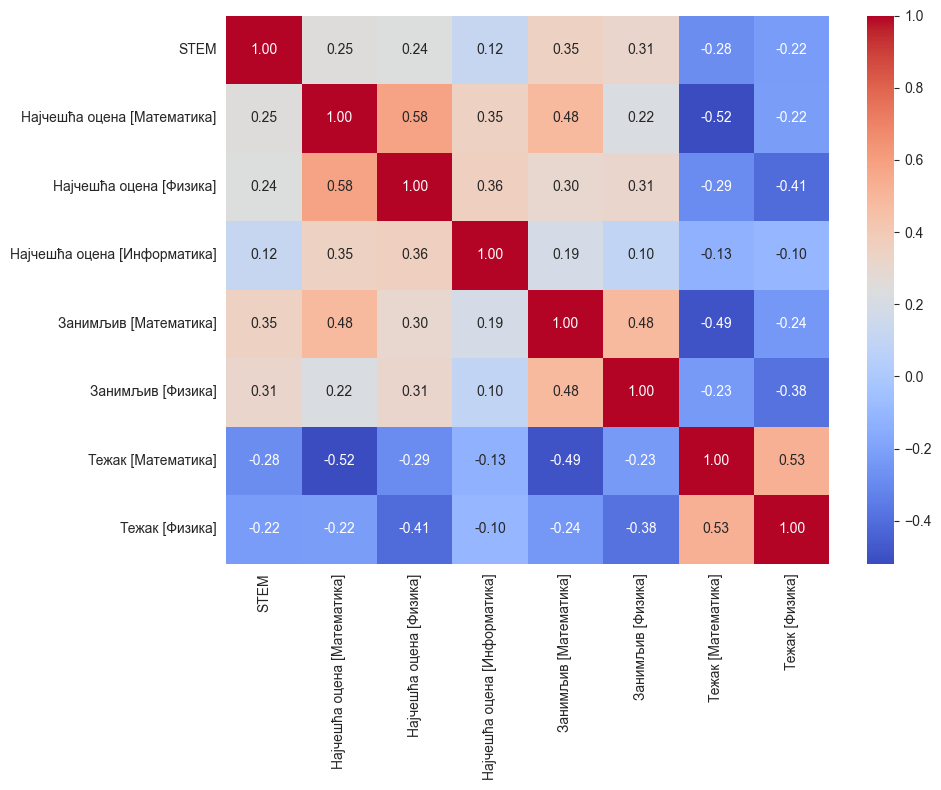

In [24]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.tight_layout()
plt.show()

**Закључак:** топлотна мапа показује да су СТЕМ опредељење и перципирана занимљивост математике (ρ=0.35) и физике (ρ=0.31) најјаче позитивно повезани показатељи у овом избору, док су перципирана тежина ова два предмета негативно повезана са СТЕМ опредељењем (ρ=-0.28 за математику, ρ=-0.22 за физику) — ученици који сматрају ове предмете тежим ређе бирају СТЕМ смер. Најчешћа оцена из математике и физике показује слабију, али и даље позитивну повезаност (ρ=0.25 и ρ=0.24). Међу самим предикторима, најизраженија је негативна веза између оцене и перципиране тежине математике (ρ=-0.52) — очекивано, ученици који предмет доживљавају као тежак у просеку имају ниже оцене.

# 3. Статистички тестови

У овом одељку формално тестирамо да ли постоји статистички значајна разлика или повезаност између STEM и не-STEM групе, за показатеље описане и приказане графички у наставку. Користе се два типа тестова:

- **t-тест за независне узорке** (Welch-ова варијанта, `equal_var=False`): за поређење просечне вредности нумеричке/ординалне променљиве (оцене, тежина, занимљивост, корисност) између две групе. Смер хипотезе (једнострано или двострано) наведен је уз сваки тест; тамо где се истовремено тестира више предмета за исту хипотезу, примењена је **Бонферонијева корекција** прага значајности.
- **χ² тест независности**: за две категоријске променљиве (нпр. пол × STEM, место одрастања × STEM) на контингенцијској табели, уз проверу претпоставке о минималним очекиваним фреквенцијама (све ≥ 5).

## 3.1. Оцене из STEM предмета: да ли STEM ученици имају боље оцене?

Поредимо **најчешће оцене** из типичних STEM предмета у основној школи (математика, физика, информатика, хемија, биологија — само колоне које постоје у `X`) између група **STEM** и **не-STEM**. Приказујемо **просек** по групи и **Welch t-тест** (`equal_var=False`) са `alternative='greater'`: хипотеза да је просек у STEM групи **већи** од не-STEM.

Пошто се овде спроводи **пет** t-тестова над истом врстом хипотезе (различити предмети), примењена је **Бонферонијева корекција** (прилагођени праг значајности α/5) како би се контролисала вероватноћа лажно позитивног резултата услед вишеструког тестирања. Резултат: сви тестови остају статистички значајни и након корекције.

Ово поређење је **описно** у смислу групе које се пореде — не значи да је избор смера *узрок* разлике у оценама.

Просечна најчешћа оцена по групи (STEM предмети):
         Математика  Физика  Информатика  Хемија  Биологија
STEM                                                       
НЕ-СТЕМ       4.382   4.444        4.882   4.479      4.762
СТЕМ          4.779   4.783        4.947   4.767      4.859


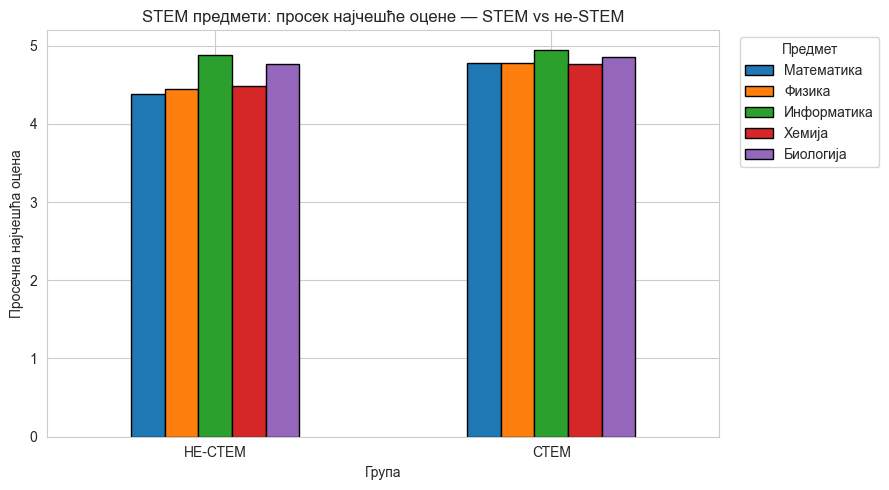

Welch t-тест, једнострано STEM > не-STEM (scipy: alternative='greater'):
Бонферонијева корекција за 5 тестова: прилагођени праг значајности = 0.05/5 = 0.0100

  Математика: t=8.437, p=0.00000 (n_stem=434, n_non=610, mean_stem=4.779, mean_non=4.382) -> значајно након Бонферонијеве корекције: да
  Физика: t=7.577, p=0.00000 (n_stem=434, n_non=610, mean_stem=4.783, mean_non=4.444) -> значајно након Бонферонијеве корекције: да
  Информатика: t=2.583, p=0.00497 (n_stem=434, n_non=610, mean_stem=4.947, mean_non=4.882) -> значајно након Бонферонијеве корекције: да
  Хемија: t=6.309, p=0.00000 (n_stem=434, n_non=610, mean_stem=4.767, mean_non=4.479) -> значајно након Бонферонијеве корекције: да
  Биологија: t=2.879, p=0.00203 (n_stem=434, n_non=610, mean_stem=4.859, mean_non=4.762) -> значајно након Бонферонијеве корекције: да


In [25]:
STEM_PREDMET_OCENE = [
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Информатика]',
    'Најчешћа оцена [Хемија]',
    'Најчешћа оцена [Биологија]',
]
stem_grade_cols = [c for c in STEM_PREDMET_OCENE if c in X.columns]

means_stem_pred = (
    X.groupby('STEM')[stem_grade_cols]
    .mean()
    .round(3)
    .rename(index=lambda k: STEM_LABELS.get(k, k))
)
means_stem_pred.columns = [
    c.replace('Најчешћа оцена [', '').replace(']', '') for c in means_stem_pred.columns
]
print('Просечна најчешћа оцена по групи (STEM предмети):')
print(means_stem_pred)

plot_stem = means_stem_pred.copy()
ax = plot_stem.plot(kind='bar', rot=0, figsize=(9, 5), edgecolor='black')
plt.ylabel('Просечна најчешћа оцена')
plt.xlabel('Група')
plt.title('STEM предмети: просек најчешће оцене — STEM vs не-STEM')
plt.legend(title='Предмет', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(stem_grade_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, једнострано STEM > не-STEM (scipy: alternative='greater'):")
print(f"Бонферонијева корекција за {m} тестова: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in stem_grade_cols:
    a = pd.to_numeric(X.loc[X['STEM'] == 1, col], errors='coerce').dropna()
    b = pd.to_numeric(X.loc[X['STEM'] == 0, col], errors='coerce').dropna()
    res = ttest_ind(a, b, equal_var=False, alternative='greater')
    predmet = col.replace('Најчешћа оцена [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.5f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )


**Закључак:** СТЕМ ученици у просеку имају више најчешће оцене од не-СТЕМ ученика у свих пет посматраних предмета (нпр. математика 4.779 наспрам 4.382, физика 4.783 наспрам 4.444, хемија 4.767 наспрам 4.479). Разлика је статистички значајна за сваки предмет и остаје значајна и после Бонферонијеве корекције за пет тестова (p=0.00497 за информатику, p=0.00203 за биологију, практично нула за остале — сви испод прилагођеног прага 0.01). Ово подржава хипотезу да СТЕМ ученици постижу боље резултате у СТЕМ предметима још у основној школи, пре него што су уопште уписали жељени смер.

## 3.2. Да ли STEM ученици доживљавају STEM предмете као лакше?

За **математику** и **физику** у основној школи питамо колико је предмет био **тежак** (Ликерт: већи број = већа пријављена тежина, типично 1–5). **Нижи просек** у групи STEM у односу на не-STEM значи да те предмете **просечно доживљавају као лакше** (мање тешке).

Хипотеза се тестира Welch t-тестом, једнострано (STEM < не-STEM), уз **Бонферонијеву корекцију** за 2 теста (математика, физика) — прилагођени праг значајности α/2.

Просечна пријављена тежина (већи број = теже; нижи просек = лакше):
         Математика  Физика
НЕ-СТЕМ       2.856   2.872
СТЕМ          2.081   2.293


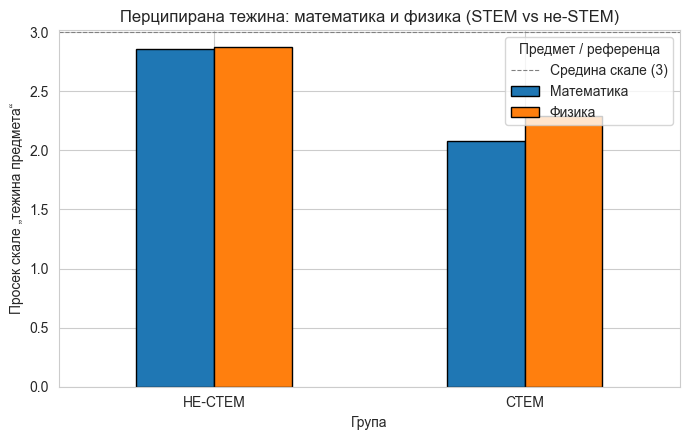

Welch t-тест, једнострано STEM < не-STEM (scipy: alternative='less'):
Бонферонијева корекција за 2 теста: прилагођени праг значајности = 0.05/2 = 0.0250

  Математика: t=-9.471, p=0.000000 (n_stem=434, n_non=610, mean_stem=2.081, mean_non=2.856) -> значајно након Бонферонијеве корекције: да
  Физика: t=-7.428, p=0.000000 (n_stem=434, n_non=610, mean_stem=2.293, mean_non=2.872) -> значајно након Бонферонијеве корекције: да


In [26]:
tez_cols = ['Тежак [Математика]', 'Тежак [Физика]']
tmp = X[['STEM']].copy()
for c in tez_cols:
    tmp[c] = X[c].map(_likert_u_broj)

means_tez = tmp.groupby('STEM')[tez_cols].mean().round(3)
means_tez.columns = ['Математика', 'Физика']
means_tez.index = [STEM_LABELS.get(i, i) for i in means_tez.index]

print('Просечна пријављена тежина (већи број = теже; нижи просек = лакше):')
print(means_tez)

ax = means_tez.plot(kind='bar', rot=0, figsize=(7, 4.5), edgecolor='black')
plt.ylabel('Просек скале „тежина предмета“')
plt.xlabel('Група')
plt.title('Перципирана тежина: математика и физика (STEM vs не-STEM)')
plt.axhline(y=3, color='grey', linestyle='--', linewidth=0.8, label='Средина скале (3)')
plt.legend(title='Предмет / референца')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(tez_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, једнострано STEM < не-STEM (scipy: alternative='less'):")
print(f"Бонферонијева корекција за {m} теста: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in tez_cols:
    a = tmp.loc[tmp['STEM'] == 1, col].dropna()
    b = tmp.loc[tmp['STEM'] == 0, col].dropna()
    res = ttest_ind(a, b, equal_var=False, alternative='less')
    predmet = col.replace('Тежак [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.6f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )

**Закључак:** СТЕМ ученици перципирају математику (просек 2.081 наспрам 2.856) и физику (2.293 наспрам 2.872) као знатно лакше него не-СТЕМ ученици — обе разлике су високо статистички значајне и после Бонферонијеве корекције (p<0.000001 за оба предмета, праг 0.025). Ово потврђује да ученици који бирају СТЕМ смер имају позитивнији однос према тежини ових предмета, а не само боље оцене.

## 3.3. Да ли су им занимљивији STEM предмети (математика и физика)?

За **математику** и **физику** у основној школи питамо колико је предмет био **занимљив** (Ликерт, типично 1–5: **већи број = већа пријављена занимљивост**). **Виши просек** у групи STEM у односу на не-STEM значи да те предмете **просечно доживљавају као занимљивије**.

Хипотеза се тестира Welch t-тестом (двострано), уз **Бонферонијеву корекцију** за 2 теста (математика, физика) — прилагођени праг значајности α/2.

Просечна пријављена занимљивост (већи број = занимљивије; виши просек = занимљивије):
         Математика  Физика
НЕ-СТЕМ       2.918   2.400
СТЕМ          3.947   3.334


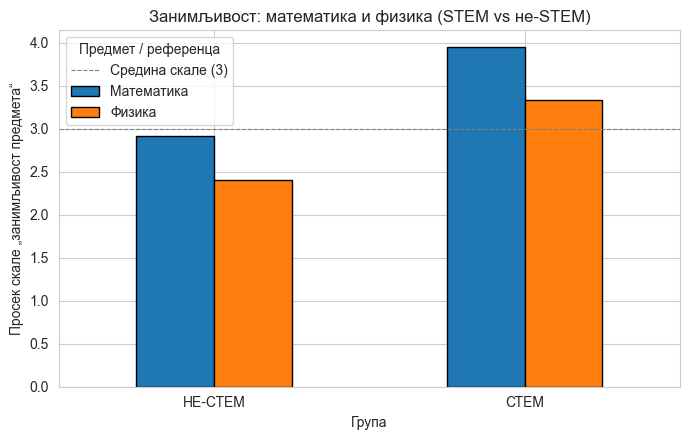

Welch t-тест, двострано (STEM vs не-STEM):
Бонферонијева корекција за 2 теста: прилагођени праг значајности = 0.05/2 = 0.0250

  Математика: t=12.143, p=0.0000000000 (n_stem=434, n_non=610, mean_stem=3.947, mean_non=2.918) -> значајно након Бонферонијеве корекције: да
  Физика: t=10.689, p=0.0000000000 (n_stem=434, n_non=610, mean_stem=3.334, mean_non=2.400) -> значајно након Бонферонијеве корекције: да


In [27]:
zan_cols = ['Занимљив [Математика]', 'Занимљив [Физика]']
tmp_z = X[['STEM']].copy()
for c in zan_cols:
    tmp_z[c] = X[c].map(_likert_u_broj)

means_zan = tmp_z.groupby('STEM')[zan_cols].mean().round(3)
means_zan.columns = ['Математика', 'Физика']
means_zan.index = [STEM_LABELS.get(i, i) for i in means_zan.index]

print('Просечна пријављена занимљивост (већи број = занимљивије; виши просек = занимљивије):')
print(means_zan)

ax = means_zan.plot(kind='bar', rot=0, figsize=(7, 4.5), edgecolor='black')
plt.ylabel('Просек скале „занимљивост предмета“')
plt.xlabel('Група')
plt.title('Занимљивост: математика и физика (STEM vs не-STEM)')
plt.axhline(y=3, color='grey', linestyle='--', linewidth=0.8, label='Средина скале (3)')
plt.legend(title='Предмет / референца')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(zan_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, двострано (STEM vs не-STEM):")
print(f"Бонферонијева корекција за {m} теста: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in zan_cols:
    a = tmp_z.loc[tmp_z['STEM'] == 1, col].dropna()
    b = tmp_z.loc[tmp_z['STEM'] == 0, col].dropna()
    res = ttest_ind(a, b, equal_var=False)
    predmet = col.replace('Занимљив [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.10f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )

**Закључак:** СТЕМ ученици оцењују математику (просек 3.947 наспрам 2.918) и физику (3.334 наспрам 2.400) као знатно занимљивије него не-СТЕМ ученици — разлика прелази један поен на скали 1–5 за оба предмета и статистички је високо значајна и после Бонферонијеве корекције (p<0.0001, праг 0.025). Занимљивост предмета показује се као један од најизраженијих показатеља СТЕМ опредељења међу свим до сада разматраним варијаблама.

## 3.4. Да ли су им кориснији STEM предмети (математика и физика)?

За **математику** и **физику** у основној школи питамо колико је предмет био **користан** (Ликерт, типично 1–5: **већи број = већа пријављена корисност**). **Виши просек** у групи STEM у односу на не-STEM значи да **у просеку приписују већу корисност** тим предметима на скали.

Хипотеза се тестира Welch t-тестом, једнострано (STEM > не-STEM), уз **Бонферонијеву корекцију** за 2 теста (математика, физика) — прилагођени праг значајности α/2.

Просечна пријављена корисност (већи број = корисније; виши просек = корисније):
         Математика  Физика
НЕ-СТЕМ       3.574   2.702
СТЕМ          4.200   3.380


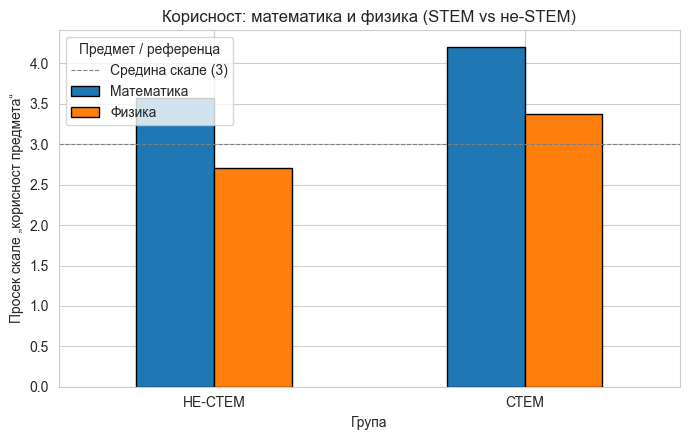

Welch t-тест, једнострано STEM > не-STEM (scipy: alternative='greater'):
Бонферонијева корекција за 2 теста: прилагођени праг значајности = 0.05/2 = 0.0250

  Математика: t=7.999, p=0.0000000000 (n_stem=434, n_non=610, mean_stem=4.200, mean_non=3.574) -> значајно након Бонферонијеве корекције: да
  Физика: t=7.864, p=0.0000000000 (n_stem=434, n_non=610, mean_stem=3.380, mean_non=2.702) -> значајно након Бонферонијеве корекције: да


In [28]:
kor_cols = ['Корисан [Математика]', 'Корисан [Физика]']
tmp_k = X[['STEM']].copy()
for c in kor_cols:
    tmp_k[c] = X[c].map(_likert_u_broj)

means_kor = tmp_k.groupby('STEM')[kor_cols].mean().round(3)
means_kor.columns = ['Математика', 'Физика']
means_kor.index = [STEM_LABELS.get(i, i) for i in means_kor.index]

print('Просечна пријављена корисност (већи број = корисније; виши просек = корисније):')
print(means_kor)

ax = means_kor.plot(kind='bar', rot=0, figsize=(7, 4.5), edgecolor='black')
plt.ylabel('Просек скале „корисност предмета“')
plt.xlabel('Група')
plt.title('Корисност: математика и физика (STEM vs не-STEM)')
plt.axhline(y=3, color='grey', linestyle='--', linewidth=0.8, label='Средина скале (3)')
plt.legend(title='Предмет / референца')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(kor_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, једнострано STEM > не-STEM (scipy: alternative='greater'):")
print(f"Бонферонијева корекција за {m} теста: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in kor_cols:
    a = tmp_k.loc[tmp_k['STEM'] == 1, col].dropna()
    b = tmp_k.loc[tmp_k['STEM'] == 0, col].dropna()
    res = ttest_ind(a, b, equal_var=False, alternative='greater')
    predmet = col.replace('Корисан [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.10f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )

**Закључак:** СТЕМ ученици перципирају математику (просек 4.200 наспрам 3.574) и физику (3.380 наспрам 2.702) као корисније за своју будућност него не-СТЕМ ученици — разлика је статистички високо значајна и после Бонферонијеве корекције (p<0.0001, праг 0.025) за оба предмета. Заједно са резултатима из 3.1–3.3, ово показује конзистентан образац: СТЕМ ученици имају боље оцене и доживљавају ове предмете као лакше, занимљивије и корисније.

## 3.5. $\chi^2$ тест независности (пол × STEM)

Градимо контингенцијску табелу и примењујемо `chi2_contingency` из SciPy.

In [29]:
ct = pd.crosstab(X['Пол:'], X['STEM'], margins=True)
print(ct)

ct_core = pd.crosstab(X['Пол:'], X['STEM'])
chi2, p, dof, expected = chi2_contingency(ct_core)
print(f'χ² = {chi2:.4f}, p-value = {p:.6f}, степени слободе = {dof}')

print('\nОчекиване фреквенције (претпоставка χ² теста: све ≥ 5):')
expected_df = pd.DataFrame(expected, index=ct_core.index, columns=ct_core.columns).round(2)
print(expected_df)
print(f"\nНајмања очекивана фреквенција: {expected.min():.2f} "
      f"-> претпоставка {'испуњена' if expected.min() >= 5 else 'НИЈЕ испуњена'}")

STEM      0    1   All
Пол:                  
женски  476  239   715
мушки   134  195   329
All     610  434  1044
χ² = 60.8990, p-value = 0.000000, степени слободе = 1

Очекиване фреквенције (претпоставка χ² теста: све ≥ 5):
STEM         0       1
Пол:                  
женски  417.77  297.23
мушки   192.23  136.77

Најмања очекивана фреквенција: 136.77 -> претпоставка испуњена


**Закључак:** постоји статистички значајна повезаност између пола и СТЕМ опредељења (χ²=60.899, p<0.000001, степени слободе = 1; претпоставка о минималној очекиваној фреквенцији испуњена, минимум 136.77). Мушки ученици бирају СТЕМ смер пропорционално чешће (195 од 329, ≈59.3%) него женски ученици (239 од 715, ≈33.4%), у складу са небалансираном родном структуром узорка примећеном у одељку 2.2.

## 3.6. $\chi^2$ тест независности (Одрастао/ла сам у: × STEM)

Иста логика, за место одрастања (град/варошица/село) наспрам STEM опредељења.

In [30]:
ct_odrastao = pd.crosstab(X['Одрастао/ла сам у:'], X['STEM'], margins=True)
print(ct_odrastao)

ct_odrastao_core = pd.crosstab(X['Одрастао/ла сам у:'], X['STEM'])
chi2, p, dof, expected = chi2_contingency(ct_odrastao_core)
print(f'χ² = {chi2:.4f}, p-value = {p:.6f}, степени слободе = {dof}')

print('\nОчекиване фреквенције (претпоставка χ² теста: све ≥ 5):')
expected_df = pd.DataFrame(expected, index=ct_odrastao_core.index, columns=ct_odrastao_core.columns).round(2)
print(expected_df)
print(f"\nНајмања очекивана фреквенција: {expected.min():.2f} "
      f"-> претпоставка {'испуњена' if expected.min() >= 5 else 'НИЈЕ испуњена'}")

STEM                  0    1   All
Одрастао/ла сам у:                
варошици             62   33    95
већем граду         399  313   712
мањем граду          47   51    98
селу                102   37   139
All                 610  434  1044
χ² = 20.7175, p-value = 0.000120, степени слободе = 3

Очекиване фреквенције (претпоставка χ² теста: све ≥ 5):
STEM                     0       1
Одрастао/ла сам у:                
варошици             55.51   39.49
већем граду         416.02  295.98
мањем граду          57.26   40.74
селу                 81.22   57.78

Најмања очекивана фреквенција: 39.49 -> претпоставка испуњена


**Закључак:** постоји статистички значајна повезаност између места одрастања и СТЕМ опредељења (χ²=20.7175, p=0.00012, степени слободе = 3; претпоставка о минималној очекиваној фреквенцији испуњена, минимум 39.49). Удео СТЕМ ученика варира од ≈26.6% (село) и ≈34.7% (варошица) до ≈44.0% (већи град) и чак ≈52.0% (мањи град) — ученици из села пропорционално најређе бирају СТЕМ смер, док они из мањих градова то чине најчешће.

# 4. Предобрада података за моделовање

Пре него што подаци буду коришћени за тренирање предиктивних модела, потребно је спровести низ корака предобраде: уклањање непотребних/ризичних колона, обраду недостајућих вредности, детекцију дупликата и аномалија, енкодирање категоријских и скалирање нумеричких обележја, поделу на тренинг/тест скуп и селекцију обележја.

## 4.1. Уклањање непотребних колона

### Претходно већ искључене колоне

Пет колона је искључено раније, у одељку 1.4.1, приликом дефинисања матрице обележја `X`: `Timestamp` и четири слободнотекстуалне колоне (`Занимање твоје мајке:`, `Занимање твог оца:`, `Зашто сте изабрали да упишите Гимназију?`, `Зашто сте изабрали да упишете овај смер?`). Разлог је исти као и овде — описни/слободнотекстуални карактер који захтева NLP или додатно кодирање пре него што би могле да се користе као обележја модела.

### Циљна променљива и њен извор

Из `X` уклањамо и:

- **`STEM`** — сама циљна променљива не сме бити присутна међу улазним обележјима модела.
- **`Смер:`** — изворна колона из које је `STEM` директно изведена (правило: 1 ако вредност припада листи `stem_smerovi`, иначе 0); њено задржавање би представљало директно „цурење“ циљне вредности у модел (data leakage).

### Административне/институционалне колоне (нису прави фактор опредељења)

Поред горе наведеног, уклањамо и следеће три колоне:

- **`Похађам средњу школу:`** — идентитет једне од четири конкретне школе из узорка. Иако би ова колона потенцијално могла показати одређену повезаност са циљном променљивом (нпр. ако поједине школе структурно нуде специфична СТЕМ одељења, попут раног специјализованог математичког одељења), таква повезаност не би представљала реалну слику стварних фактора опредељења ученика, већ институционалну/понудну карактеристику конкретне школе — не лични фактор о коме овај рад говори. Такође, задржавање овакве колоне не би било генерализабилно ван ова четири конкретне школе из узорка.
- **`Разред:`** и **`Година рођења:`** — обе колоне носе слаб, али реалан сигнал искључиво преко исте уске подгрупе ученика у раним специјализованим одељењима (сви редови са `Разред: 7` или `8`, као и рођени 2010/2011. године, припадају СТЕМ групи — видети одељак 1.3.1). Хронолошки, тренутни разред и година рођења не могу бити *разлог* избора смера јер се одређују независно од (и после) саме одлуке о упису; њихова привидна предиктивна моћ потиче искључиво од исте институционалне особености, а не од стварног фактора опредељења.

**Напомена:** уклањање ових колона из `X` не значи да се подаци губе — `df` и даље садржи све оригиналне колоне и могу се користити за било какву описну анализу, подгрупне прегледе или анализу робусности касније у раду.

In [31]:
kolone_za_izbacivanje_4_1 = [
    'STEM',
    'Смер:',
    'Похађам средњу школу:',
    'Разред:',
    'Година рођења:',
]

print('Број колона у X пре уклањања:', X.shape[1])

X = X.drop(columns=kolone_za_izbacivanje_4_1)

print('Број уклоњених колона:', len(kolone_za_izbacivanje_4_1))
print('Број колона у X после уклањања:', X.shape[1])
print('\nПреостале колоне у X:')
print(X.columns.tolist())

Број колона у X пре уклањања: 101
Број уклоњених колона: 5
Број колона у X после уклањања: 96

Преостале колоне у X:
['Пол:', 'Одрастао/ла сам у:', 'Основну школу сам завршио/ла у:', 'Стручна спрема твоје мајке:', 'Стручна спрема твог оца:', 'Колико има деце у твојој породици, рачунајући и тебе (упиши број):', 'Какав си био/ла ђак у основној школи?', 'Најомиљенији предмет:', 'Други омиљени предмет (омиљени предмет, мање омиљени од претходног):', 'Трећи омиљени предмет (омиљени предмет, мање омиљени од претходна два):', 'Тежак [Српски језик и књижевност]', 'Тежак [Енглески језик]', 'Тежак [2. страни језик]', 'Тежак [Историја]', 'Тежак [Географија]', 'Тежак [Биологија]', 'Тежак [Математика]', 'Тежак [Информатика]', 'Тежак [Физика]', 'Тежак [Хемија]', 'Тежак [Музичка култура]', 'Тежак [Ликовна култура]', 'Тежак [Физичко васпитање]', 'Тежак [Техника и технологија]', 'Корисан [Српски језик и књижевност]', 'Корисан [Енглески језик]', 'Корисан [2. страни језик]', 'Корисан [Историја]', 'Кориса

## 4.2. Обрада недостајућих вредности

Проверавамо да ли је, након уклањања колона у одељку 4.1, потребна додатна обрада недостајућих вредности. У одељку 1.1.1 је већ утврђено да изворни скуп података нема ниједну недостајућу вредност; овде проверавамо да ли је нека од претходних трансформација (нпр. претварање Ликерт одговора у бројеве у одељку 2.5.1) можда унела нове недостајуће вредности у `X`.

In [32]:
missing_X = X.isna().sum()
missing_X_cols = missing_X[missing_X > 0]

if len(missing_X_cols) == 0:
    print("Нема недостајућих вредности ни у једној од", X.shape[1], "преосталих колона у X.")
else:
    print(f"Број колона са недостајућим вредностима: {len(missing_X_cols)}")
    print(missing_X_cols)

Нема недостајућих вредности ни у једној од 96 преосталих колона у X.


**Закључак:** `X` и даље нема ниједну недостајућу вредност — ни уклањање колона у 4.1, ни ранија конверзија Ликерт одговора у бројеве нису унели нове `NaN` вредности. Пошто нема недостајућих вредности, импутација (нпр. попуњавање медијаном/модом) овде није потребна. Овај корак ипак остаје документован као стандардни део тока предобраде, и био би неопходан да се модел касније примени на нове, стварне податке који могу садржати недостајуће одговоре.

## 4.3. Детекција дупликата

Проверавамо да ли скуп података садржи потпуно идентичне (дуплиране) редове, занемарујући колону `Timestamp` — различито време уноса не значи да су одговори заиста различити, јер је исти ученик могао случајно послати анкету два пута.

In [33]:
df_bez_timestamp = df.drop(columns=['Timestamp'])
duplikati_mask = df_bez_timestamp.duplicated(keep=False)

print(f"Број редова укључених у неки дупликат (занемарујући Timestamp): {duplikati_mask.sum()}")
print(df.loc[duplikati_mask, ['Timestamp', 'Пол:', 'Година рођења:', 'Похађам средњу школу:', 'Смер:', 'Разред:']])

Број редова укључених у неки дупликат (занемарујући Timestamp): 2
                  Timestamp   Пол:  Година рођења:  \
634 2023-12-15 09:15:43.378  мушки            2009   
636 2023-12-15 11:17:37.350  мушки            2009   

            Похађам средњу школу:       Смер:  Разред:  
634  Другу крагујевачку гимназију  општи смер      1.0  
636  Другу крагујевачку гимназију  општи смер      1.0  


**Закључак:** пронађена су два реда (индекси 634 и 636) која су идентична у свим одговорима осим у `Timestamp`-у — оба потичу од ученика мушког пола, рођеног 2009. године, из Друге крагујевачке гимназије, општег смера, 1. разреда, поднета истог дана са размаком од само два сата. Идентичност преко готово 100 питања практично искључује случајну подударност — ово веома вероватно представља исто лице које је нехотично попунило анкету два пута. Задржавамо први унос (индекс 634), а каснији дупликат (индекс 636) уклањамо — из `df`, `X` и `y`, како би сви остали међусобно усклађени.

In [34]:
duplikati_za_brisanje = df_bez_timestamp[df_bez_timestamp.duplicated(keep='first')].index

print(f"Индекси редова који се бришу (каснији дупликат): {duplikati_za_brisanje.tolist()}")

df = df.drop(index=duplikati_za_brisanje)
X = X.drop(index=duplikati_za_brisanje)
y = y.drop(index=duplikati_za_brisanje)

print(f"\nБрој редова: df={df.shape[0]}, X={X.shape[0]}, y={y.shape[0]}")

Индекси редова који се бришу (каснији дупликат): [636]

Број редова: df=1043, X=1043, y=1043


## 4.4. Детекција аномалија

Детектујемо изразите аутлајере/аномалије у подацима помоћу Isolation Forest алгоритма, примењеног на нумеричке колоне у `X` (категоријске колоне се енкодирају тек у наредном одељку 4.5, па се овде не укључују). Са подразумеваном `contamination='auto'` вредношћу алгоритам означава непрактично велик удео узорка као аномалију (преко трећине свих редова), што показује да овако висока димензионалност (86 нумеричких колона) захтева фиксирану, мању вредност `contamination` параметра.

Поред Isolation Forest резултата, проверавамо и једноставнији, лакше тумачив показатељ: **број различитих вредности које је сваки ученик користио** кроз свих ~86 нумеричких (оцена и Ликерт) питања. Ученик који искрено и пажљиво одговара на толико разнородних питања (о 14 различитих предмета и темама попут навика учења, подршке родитеља, итд.) готово сигурно ће искористити већи део опсега скале (1–5). Одговор који кроз готово 90 различитих питања користи само 2–3 вредности представља класичан образац „straight-lining“ — небрижљивог/аутоматског попуњавања анкете без читања питања — а не стваран, нијансиран став ученика.

In [35]:
from sklearn.ensemble import IsolationForest

numericke_kolone = X.select_dtypes(include=[np.number]).columns.tolist()
print(f"Број нумеричких колона укључених у детекцију: {len(numericke_kolone)} од укупно {X.shape[1]}")

iso_forest = IsolationForest(contamination=0.02, random_state=42)
if_oznake = pd.Series(
    iso_forest.fit_predict(X[numericke_kolone]),
    index=X.index,
)

print(f"Isolation Forest означио као аномалију: {(if_oznake == -1).sum()} редова ({(if_oznake == -1).mean() * 100:.1f}%)")

Број нумеричких колона укључених у детекцију: 86 од укупно 96
Isolation Forest означио као аномалију: 21 редова (2.0%)


In [36]:
broj_jedinstvenih = X[numericke_kolone].nunique(axis=1)

print("Расподела броја различитих вредности по реду:")
print(broj_jedinstvenih.value_counts().sort_index())

PRAG_JEDINSTVENIH = 3
straight_lining = broj_jedinstvenih[broj_jedinstvenih <= PRAG_JEDINSTVENIH]

preklapanje = sum(idx in if_oznake[if_oznake == -1].index for idx in straight_lining.index)
print(f"\nБрој редова са ≤{PRAG_JEDINSTVENIH} различите вредности кроз {len(numericke_kolone)} питања: {len(straight_lining)}")
print(f"Од тога, колико их је Isolation Forest такође означио: {preklapanje}/{len(straight_lining)}")

print("\nВредности које су ти ученици користили:")
for idx in straight_lining.index:
    print(f"  Индекс {idx}: {sorted(X.loc[idx, numericke_kolone].unique())}")

Расподела броја различитих вредности по реду:
2       5
3       3
4      19
5    1016
Name: count, dtype: int64

Број редова са ≤3 различите вредности кроз 86 питања: 8
Од тога, колико их је Isolation Forest такође означио: 4/8

Вредности које су ти ученици користили:
  Индекс 23: [np.int64(1), np.int64(3), np.int64(5)]
  Индекс 226: [np.int64(3), np.int64(5)]
  Индекс 227: [np.int64(1), np.int64(2), np.int64(5)]
  Индекс 368: [np.int64(1), np.int64(5)]
  Индекс 454: [np.int64(1), np.int64(5)]
  Индекс 460: [np.int64(1), np.int64(2), np.int64(5)]
  Индекс 561: [np.int64(1), np.int64(5)]
  Индекс 562: [np.int64(1), np.int64(5)]


**Закључак:** од укупно 1043 реда, чак 1016 (≈97%) користи свих пет вредности скале, што потврђује да је варијација одговора уобичајена и очекивана. Само 8 редова показује изразит образац „straight-lining“ — коришћење свега 2–3 (готово увек само крајњих, 1 и 5) вредности кроз скоро 90 различитих питања о 14 предмета и разноврсним темама, што није реалистичан образац искреног одговарања.

Ови редови се преклапају само делимично са скупом који је означио Isolation Forest (4/8) — Isolation Forest мери вишедимензионалну удаљеност од центра узорка, па пропушта случајеве попут константног наизменичног одговора „1“/„5“ на свако питање (који, у зависности од распореда, не мора деловати изразито удаљено у сваком појединачном правцу, али је сам по себи неуверљив образац). Зато ове редове уклањамо на основу директног, тумачивог критеријума (број различитих вредности), а не искључиво на основу Isolation Forest резултата.

Редове које је Isolation Forest означио, али који не показују овај образац, **задржавамо** — то су вероватно само ученици са стварно необичним, али уверљивим комбинацијама одговора, чије уклањање би без јасног оправдања нарушило разноврсност узорка важну за анализу правих фактора опредељења.

In [37]:
df = df.drop(index=straight_lining.index)
X = X.drop(index=straight_lining.index)
y = y.drop(index=straight_lining.index)

print(f"Број редова после уклањања аномалија: df={df.shape[0]}, X={X.shape[0]}, y={y.shape[0]}")

Број редова после уклањања аномалија: df=1035, X=1035, y=1035


## 4.5. Енкодирање категоријских променљивих

Категоријске (текстуалне) променљиве трансформишемо у нумерички облик погодан за моделе машинског учења. Преостале категоријске колоне у `X` делимо у две групе:

- **Номиналне** (немају природан редослед): `Пол:`, `Најомиљенији предмет:`, `Други омиљени предмет...`, `Трећи омиљени предмет...`. Ове колоне енкодирамо **one-hot** методом (`pd.get_dummies`).
- **Ординалне** (имају природан редослед): `Одрастао/ла сам у:` и `Основну школу сам завршио/ла у:` (село < варошица < мањи град < већи град, по степену урбанизације), `Стручна спрема твоје мајке:`/`твог оца:` (основна < средња < виша школа < факултет) и `Какав си био/ла ђак у основној школи?` (добар/а < врло добар/а < одличан/а — мапирано на исту 3–5 скалу која се користи за оцене у остатку података). Ове колоне мапирамо ручно на растуће целе бројеве, чиме се чува редослед који би one-hot енкодирање изгубило.

### Успутно откривен проблем: `Колико има деце у твојој породици...`

Приликом покушаја да ову колону протумачимо као број, откривамо да један ред садржи вредност `/` уместо броја. Ово није уочено у одељку 4.2 зато што `isna()` провера препознаје само праве `NaN`/`None` вредности — `/` је потпуно валидан текстуални карактер у object колони, само семантички неисправан за бројчано поље. Проблем постаје видљив тек када покушамо да га протумачимо као број, што радимо управо овде. Недостајућу вредност попуњавамо медијаном колоне.

In [38]:
deca_kolona = 'Колико има деце у твојој породици, рачунајући и тебе (упиши број):'

X[deca_kolona] = pd.to_numeric(X[deca_kolona], errors='coerce')
broj_nevalidnih = X[deca_kolona].isna().sum()
print(f"Број редова где вредност није могла да се протумачи као број: {broj_nevalidnih}")

medijana_dece = X[deca_kolona].median()
X[deca_kolona] = X[deca_kolona].fillna(medijana_dece)
print(f"Попуњено медијаном: {medijana_dece}")

Број редова где вредност није могла да се протумачи као број: 1
Попуњено медијаном: 2.0


In [39]:
urbanizacija_mapa = {
    'селу': 1,
    'варошици': 2,
    'мањем граду': 3,
    'већем граду': 4,
}

X['Одрастао/ла сам у:'] = X['Одрастао/ла сам у:'].map(urbanizacija_mapa)
X['Основну школу сам завршио/ла у:'] = X['Основну школу сам завршио/ла у:'].map(urbanizacija_mapa)

obrazovanje_mapa = {
    'завршена основна школа': 1,
    'завршена средња школа': 2,
    'завршена виша школа': 3,
    'завршен факултет': 4,
}

X['Стручна спрема твоје мајке:'] = X['Стручна спрема твоје мајке:'].map(obrazovanje_mapa)
X['Стручна спрема твог оца:'] = X['Стручна спрема твог оца:'].map(obrazovanje_mapa)

djak_mapa = {
    'добар/а': 3,
    'врло добар/а': 4,
    'одличан/а': 5,
}

X['Какав си био/ла ђак у основној школи?'] = X['Какав си био/ла ђак у основној школи?'].map(djak_mapa)

ordinalne_kolone = [
    'Одрастао/ла сам у:',
    'Основну школу сам завршио/ла у:',
    'Стручна спрема твоје мајке:',
    'Стручна спрема твог оца:',
    'Какав си био/ла ђак у основној школи?',
]
print('Број недостајућих вредности после ординалног мапирања (треба да буде 0 за све):')
print(X[ordinalne_kolone].isna().sum())

Број недостајућих вредности после ординалног мапирања (треба да буде 0 за све):
Одрастао/ла сам у:                       0
Основну школу сам завршио/ла у:          0
Стручна спрема твоје мајке:              0
Стручна спрема твог оца:                 0
Какав си био/ла ђак у основној школи?    0
dtype: int64


In [40]:
nominalne_kolone = [
    'Пол:',
    'Најомиљенији предмет:',
    'Други омиљени предмет (омиљени предмет, мање омиљени од претходног):',
    'Трећи омиљени предмет (омиљени предмет, мање омиљени од претходна два):',
]

print('Број колона у X пре one-hot енкодирања:', X.shape[1])

X = pd.get_dummies(X, columns=nominalne_kolone, drop_first=True)

print('Број колона у X после one-hot енкодирања:', X.shape[1])

preostale_object_kolone = X.select_dtypes(include='object').columns.tolist()
print(f"\nПреостале object (некодиране) колоне у X: {preostale_object_kolone}")
print('Укупан број недостајућих вредности у X:', X.isna().sum().sum())

Број колона у X пре one-hot енкодирања: 96
Број колона у X после one-hot енкодирања: 132

Преостале object (некодиране) колоне у X: []
Укупан број недостајућих вредности у X: 0


**Закључак:** `X` је сада потпуно нумерички (нема више ниједне object колоне) и нема недостајућих вредности. One-hot енкодирање номиналних колона (пол и три омиљена предмета, сваки са 14 категорија) знатно је повећало укупан број колона; ординалне колоне су мапиране на растуће бројеве уместо да буду разложене на индикаторске колоне, чиме је сачуван њихов природни редослед.

## 4.6. Подела скупа података

Скуп података делимо на тренинг и тест подскуп (stratified train-test split), уз стратификацију по циљној променљивој `STEM` како би удео STEM/не-STEM ученика остао приближно исти у оба подскупа.

Ову поделу радимо **пре** скалирања (одељак 4.7) и селекције обележја (одељак 4.8), управо да би те наредне кораке могли исправно да применимо: обучимо (`fit`) искључиво на тренинг скупу, а затим исту, већ научену трансформацију применимо и на тест скуп — тако тест скуп остаје потпуно независан од параметара коришћених за тренирање модела.

In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Тренинг скуп: {X_train.shape[0]} редова")
print(f"Тест скуп: {X_test.shape[0]} редова")

print("\nУдео STEM у тренинг скупу:")
print(y_train.value_counts(normalize=True).round(4))
print("\nУдео STEM у тест скупу:")
print(y_test.value_counts(normalize=True).round(4))

Тренинг скуп: 828 редова
Тест скуп: 207 редова

Удео STEM у тренинг скупу:
STEM
0    0.587
1    0.413
Name: proportion, dtype: float64

Удео STEM у тест скупу:
STEM
0    0.5845
1    0.4155
Name: proportion, dtype: float64


**Закључак:** скуп је подељен у односу 80/20 (828 тренинг / 207 тест редова). Захваљујући стратификацији по `STEM`, удео STEM ученика остаје готово идентичан у оба подскупа (≈41.3% у тренинг скупу, ≈41.6% у тест скупу) — веома близу укупном уделу у целом скупу података. Од овог тренутка, `X_train`/`y_train` користимо за обучавање (`fit`) свих наредних трансформација (скалирање, селекција обележја) и модела, а `X_test`/`y_test` искључиво за коначну евалуацију.

## 4.7. Скалирање нумеричких обележја

Скалирање нумеричких обележја (нпр. `StandardScaler`) рачуна статистике — средњу вредност и стандардну девијацију — на основу података на којима се позива `fit`. Када би се то урадило пре поделе на тренинг/тест скуп, те статистике би „виделе“ и податке који треба да остану потпуно независни у тест скупу — благ облик цурења података (data leakage): резултати евалуације модела на тест скупу више не би били потпуно непристрасни, јер би параметри трансформације већ „знали“ нешто о тест подацима.

Зато скалирање радимо тек овде, **после** поделе из одељка 4.6: `scaler` се обучава (`fit`) искључиво на тренинг скупу, а затим се иста, већ научена трансформација (`transform`) примењује и на тренинг и на тест скуп. На овај начин тест скуп остаје потпуно независан од параметара коришћених за трансформацију.

In [42]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

kolone_za_proveru = ['Најчешћа оцена [Математика]', 'Најчешћа оцена [Физика]']

print('Пример пре скалирања (тренинг скуп):')
print(X_train[kolone_za_proveru].head(3))

print('\nПример после скалирања (тренинг скуп):')
print(X_train_scaled[kolone_za_proveru].head(3))

print('\nСредња вредност и стандардна девијација после скалирања — тренинг скуп (треба да буду ~0 и ~1):')
print(X_train_scaled[kolone_za_proveru].agg(['mean', 'std']))

print('\nСредња вредност и стандардна девијација после скалирања — тест скуп (не мора бити тачно 0/1, јер scaler није обучаван на њему):')
print(X_test_scaled[kolone_za_proveru].agg(['mean', 'std']))

Пример пре скалирања (тренинг скуп):
     Најчешћа оцена [Математика]  Најчешћа оцена [Физика]
716                            5                        5
415                            5                        4
498                            4                        4

Пример после скалирања (тренинг скуп):
     Најчешћа оцена [Математика]  Најчешћа оцена [Физика]
716                     0.566139                 0.544123
415                     0.566139                -0.788818
498                    -0.687239                -0.788818

Средња вредност и стандардна девијација после скалирања — тренинг скуп (треба да буду ~0 и ~1):
      Најчешћа оцена [Математика]  Најчешћа оцена [Физика]
mean                -3.582749e-16            -4.762696e-16
std                  1.000604e+00             1.000604e+00

Средња вредност и стандардна девијација после скалирања — тест скуп (не мора бити тачно 0/1, јер scaler није обучаван на њему):
      Најчешћа оцена [Математика]  Најчешћа оцена [Физик

**Закључак:** `StandardScaler` је обучен (`fit`) искључиво на `X_train`, а иста трансформација примењена и на `X_train` и на `X_test` (`transform`). Тренинг скуп после скалирања има средњу вредност ≈0 и стандардну девијацију ≈1 по конструкцији; тест скуп благо одступа од тачно 0/1 (нпр. ≈0.045 и ≈1.04 за приказане колоне), што је очекивано и исправно — тест скуп није учествовао у рачунању параметара скалирања. `X_train_scaled` и `X_test_scaled` користимо у наставку рада уместо необрађених `X_train`/`X_test`.

## 4.8. Селекција обележја

Бирамо најрелевантнија обележја за коначни модел користећи униваријантни статистички тест (`SelectKBest` са `f_classif`, ANOVA F-тест) — за свако обележје посебно се тестира да ли његова просечна вредност значајно разликује STEM и не-STEM групу, аналогно логици t-тестова из 3. поглавља. Уместо да произвољно фиксирамо број обележја (нпр. „најбољих 50“), задржавамо она чија је повезаност са циљном променљивом статистички значајна на уобичајеном прагу α = 0.05 — што је доследно приступу коришћеном раније у раду. Тест се, у складу са одељком 4.6, обучава искључиво на `X_train_scaled`/`y_train`.

In [43]:
from sklearn.feature_selection import SelectKBest, f_classif

selektor = SelectKBest(score_func=f_classif, k='all')
selektor.fit(X_train_scaled, y_train)

rezultati_selekcije = pd.DataFrame({
    'обележје': X_train_scaled.columns,
    'F_статистика': selektor.scores_,
    'p_вредност': selektor.pvalues_,
}).sort_values('p_вредност')

print('15 обележја са најнижом p-вредношћу (најзначајнија појединачна повезаност са STEM):')
print(rezultati_selekcije.head(15).to_string(index=False))

15 обележја са најнижом p-вредношћу (најзначајнија појединачна повезаност са STEM):
                                                                                                                                                          обележје  F_статистика   p_вредност
                                                                                                                                                 Занимљив [Физика]    125.502628 3.230307e-27
                                                                                                                                             Занимљив [Математика]    119.925059 3.734059e-26
                         Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Склоност ка одређеној групи предмета]     81.434988 1.249119e-18
                                                                                                                                                  Корисан [Ф

In [44]:
ALPHA = 0.05
znacajna_obelezja = rezultati_selekcije.loc[rezultati_selekcije['p_вредност'] < ALPHA, 'обележје'].tolist()

print(f"Број обележја статистички значајно повезаних са STEM (p < {ALPHA}): {len(znacajna_obelezja)} од {X_train_scaled.shape[1]}")

X_train_selected = X_train_scaled[znacajna_obelezja]
X_test_selected = X_test_scaled[znacajna_obelezja]

print(f"\nКоначна димензија: X_train_selected={X_train_selected.shape}, X_test_selected={X_test_selected.shape}")

Број обележја статистички значајно повезаних са STEM (p < 0.05): 65 од 132

Коначна димензија: X_train_selected=(828, 65), X_test_selected=(207, 65)


**Закључак:** 65 од 132 обележја (≈49%) показује статистички значајну повезаност са STEM опредељењем на прагу p < 0.05. Најзначајнија обележја — занимљивост и корисност математике/физике, перципирана тежина тих предмета, најчешће оцене из математике/физике/хемије, склоност ка одређеној групи предмета, омиљени предмет (математика) и пол — у потпуности су у складу са резултатима статистичких тестова из 3. поглавља, што додатно потврђује конзистентност налаза кроз различите методе анализе. `X_train_selected` и `X_test_selected` (132 → 65 колона) користимо у наставку рада приликом тренирања модела.

# 5. Методологија развоја и евалуације модела

Пре тренирања и поређења више модела машинског учења (наредно поглавље), дефинишемо заједничку методологију која ће се доследно применити на сваки од њих: стратегију валидације, метрике евалуације, приступ фином подешавању хиперпараметара и Nested Cross-Validation за непристрасну процену перформанси.

## 5.1. Стратегија валидације (Stratified K-Fold Cross-validation)

Дефинишемо Stratified K-Fold шему за унакрсну валидацију на тренинг скупу, која у сваком fold-у чува пропорцију STEM/не-STEM класа приближно исту као у целом тренинг скупу.

Број фолдова (K=5) стандардан је избор у литератури — довољно велики тренинг делови по фолду уз стабилну процену перформанси, а мањи од уобичајене алтернативе (K=10) због рачунске цене: ову шему касније комбинујемо са фином претрагом хиперпараметара и Nested Cross-Validation-ом на пет различитих модела, где се број тренирања брзо умножава.

In [45]:
from sklearn.model_selection import StratifiedKFold

N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

print(f"Stratified K-Fold: {N_SPLITS} фолдова")
for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train_selected, y_train), start=1):
    udeo = y_train.iloc[val_idx].mean()
    print(f"  Fold {fold}: {len(tr_idx)} тренинг / {len(val_idx)} валидациони, удео STEM у валидационом делу = {udeo:.3f}")

Stratified K-Fold: 5 фолдова
  Fold 1: 662 тренинг / 166 валидациони, удео STEM у валидационом делу = 0.410
  Fold 2: 662 тренинг / 166 валидациони, удео STEM у валидационом делу = 0.416
  Fold 3: 662 тренинг / 166 валидациони, удео STEM у валидационом делу = 0.416
  Fold 4: 663 тренинг / 165 валидациони, удео STEM у валидационом делу = 0.412
  Fold 5: 663 тренинг / 165 валидациони, удео STEM у валидационом делу = 0.412


**Закључак:** свих 5 фолдова има удео STEM ученика између 41.0% и 41.6%, готово идентично укупном уделу у тренинг скупу (≈41.3%) — стратификација ради исправно. Овај `skf` објекат (5 фолдова, `shuffle=True`, `random_state=42`) користимо доследно за унакрсну валидацију приликом поређења модела и подешавања хиперпараметара у наставку рада.

## 5.2. Метрике евалуације

Дефинишемо једну, поново употребљиву функцију за евалуацију модела која рачуна accuracy, precision, recall, F1 (macro и weighted) и ROC-AUC, и приказује confusion matrix. Ову функцију ће свих пет модела у наредном поглављу користити доследно, ради упоредивости резултата.

In [46]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
)


def evaluiraj_model(y_true, y_pred, y_proba=None, naziv_modela='Модел'):
    """Рачуна стандардне метрике евалуације за бинарну класификацију и приказује confusion matrix."""
    rezultati = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1 (weighted)': f1_score(y_true, y_pred, average='weighted'),
        'F1 (macro)': f1_score(y_true, y_pred, average='macro'),
    }
    if y_proba is not None:
        rezultati['ROC-AUC'] = roc_auc_score(y_true, y_proba)

    print(f"Метрике евалуације — {naziv_modela}:")
    for naziv, vrednost in rezultati.items():
        print(f"  {naziv}: {vrednost:.3f}")

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=['не-STEM', 'STEM'], yticklabels=['не-STEM', 'STEM'],
    )
    plt.xlabel('Предвиђено')
    plt.ylabel('Стварно')
    plt.title(f'Confusion matrix — {naziv_modela}')
    plt.tight_layout()
    plt.show()

    return rezultati, cm

Метрике евалуације — Logistic Regression (демо):
  Accuracy: 0.734
  Precision: 0.682
  Recall: 0.674
  F1 (weighted): 0.734
  F1 (macro): 0.726
  ROC-AUC: 0.798


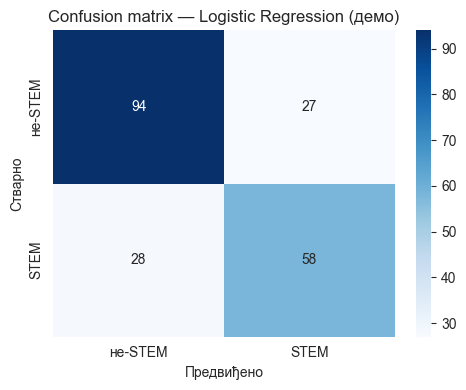

In [47]:
from sklearn.linear_model import LogisticRegression

demo_model = LogisticRegression(max_iter=1000, random_state=42)
demo_model.fit(X_train_selected, y_train)

y_pred_demo = demo_model.predict(X_test_selected)
y_proba_demo = demo_model.predict_proba(X_test_selected)[:, 1]

demo_rezultati, demo_cm = evaluiraj_model(
    y_test, y_pred_demo, y_proba_demo, naziv_modela='Logistic Regression (демо)'
)

**Закључак:** функција `evaluiraj_model` исправно рачуна све тражене метрике и приказује confusion matrix. На основном Logistic Regression моделу (без подешавања хиперпараметара), који служи само као демонстрација функције, добијамо Accuracy ≈0.73 и ROC-AUC ≈0.80 — уверљиви, разумни резултати који потврђују да низ корака предобраде из 4. поглавља исправно води до модела који уме да разликује STEM и не-STEM ученике знатно боље од случајног погађања. Стварно поређење свих пет модела следи у наредном поглављу.

## 5.3. Фино подешавање хиперпараметара

Приказујемо две технике претраге хиперпараметара — исцрпну (`GridSearchCV`) и насумичну (`RandomizedSearchCV`) — демонстриране на једном репрезентативном моделу; примена на свих пет модела следи у наредном поглављу.

### 5.3.1. GridSearchCV

Исцрпна претрага унапред задате мреже вредности хиперпараметара.

In [48]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
}

grid_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000, solver='liblinear', random_state=42),
    param_grid=param_grid,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
)
grid_search.fit(X_train_selected, y_train)

print('Најбољи параметри (GridSearchCV):', grid_search.best_params_)
print(f'Најбољи F1 (weighted) на унакрсној валидацији: {grid_search.best_score_:.3f}')

Најбољи параметри (GridSearchCV): {'C': 0.1, 'penalty': 'l1'}
Најбољи F1 (weighted) на унакрсној валидацији: 0.752


c:\Users\hplay\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\hplay\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


### 5.3.2. RandomizedSearchCV

Насумично узорковање комбинација хиперпараметара из задатих распона — ефикасније од `GridSearchCV` када је простор претраге велики.

In [49]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

param_dist = {
    'C': loguniform(1e-2, 1e2),
    'penalty': ['l1', 'l2'],
}

random_search = RandomizedSearchCV(
    estimator=LogisticRegression(max_iter=1000, solver='liblinear', random_state=42),
    param_distributions=param_dist,
    n_iter=20,
    scoring='f1_weighted',
    cv=skf,
    random_state=42,
    n_jobs=-1,
)
random_search.fit(X_train_selected, y_train)

print('Најбољи параметри (RandomizedSearchCV):', random_search.best_params_)
print(f'Најбољи F1 (weighted) на унакрсној валидацији: {random_search.best_score_:.3f}')

Најбољи параметри (RandomizedSearchCV): {'C': np.float64(0.017073967431528128), 'penalty': 'l2'}
Најбољи F1 (weighted) на унакрсној валидацији: 0.752


c:\Users\hplay\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


**Закључак:** обе технике на истом моделу (Logistic Regression) и истом простору претраге (C, penalty) налазе врло сличан резултат — F1 (weighted) ≈0.75 на унакрсној валидацији, боље од подразумеваних параметара (≈0.73 из одељка 5.2). `GridSearchCV` је прегледао свих 10 комбинација из фиксне мреже; `RandomizedSearchCV` је насумично узорковао 20 комбинација из континуалног опсега за `C`, што постаје значајно ефикасније када простор претраге буде већи (нпр. више хиперпараметара или шири опсези), као што ће бити случај код осталих модела (SVM, Random Forest, XGBoost) у наредном поглављу.

## 5.4. Nested Cross-Validation

Комбинујемо унакрсну валидацију и фино подешавање хиперпараметара кроз угнежђену (nested) шему, како бисмо добили непристрасну процену перформанси модела која није „загађена“ истим подацима коришћеним за избор хиперпараметара.

У обичној (не-угнежђеној) шеми из одељка 5.3, исти CV фолдови користе се и за бирање најбољих хиперпараметара и за извештавање о резултату тог избора — што систематски даје донекле оптимистичну процену, јер је резултат „видео“ исте податке два пута. Nested CV ово решава помоћу два нивоа унакрсне валидације: **спољашњи** ниво (`skf` из 5.1) дели тренинг скуп на делове за непристрасну процену перформанси, док се **унутрашњи** ниво (нови `inner_cv`, такође Stratified K-Fold) користи искључиво унутар сваког спољашњег дела за бирање хиперпараметара — модел никада не „види“ спољашњи тест-део фолда приликом избора параметара.

In [50]:
from sklearn.model_selection import cross_val_score

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

nested_estimator = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000, solver='liblinear', random_state=42),
    param_grid=param_grid,
    cv=inner_cv,
    scoring='f1_weighted',
)

nested_scores = cross_val_score(
    nested_estimator, X_train_selected, y_train, cv=skf, scoring='f1_weighted', n_jobs=-1
)

print('Nested CV резултати по спољашњем фолду:', nested_scores.round(3))
print(f'Nested CV просек F1 (weighted): {nested_scores.mean():.3f} ± {nested_scores.std():.3f}')
print(f'За поређење, не-угнежђени GridSearchCV.best_score_ из 5.3.1: {grid_search.best_score_:.3f}')

Nested CV резултати по спољашњем фолду: [0.772 0.745 0.736 0.746 0.76 ]
Nested CV просек F1 (weighted): 0.752 ± 0.012
За поређење, не-угнежђени GridSearchCV.best_score_ из 5.3.1: 0.752


**Закључак:** Nested CV просек (≈0.752 ± 0.012) готово је идентичан не-угнежђеном резултату из 5.3.1 (≈0.752) — у овом конкретном случају оптимистична пристрасност је занемарљива, вероватно зато што је простор претраге хиперпараметара мали (свега 10 комбинација) и модел је релативно стабилан. Ово је користан, објективан налаз сам по себи: показује да процена перформансе Logistic Regression модела није вештачки побољшана процесом подешавања хиперпараметара. Иста шема (спољашњи `skf` + унутрашњи `inner_cv` унутар `GridSearchCV`-a) примениће се доследно на свих пет модела у наредном поглављу, где разлика између угнежђене и не-угнежђене процене може бити израженија код модела са већим и осетљивијим простором хиперпараметара (нпр. SVM, Random Forest, XGBoost).

# 6. Резултати и компаративна анализа модела

У овом поглављу тренирамо и упоређујемо свих пет модела машинског учења из теоријског оквира, користећи алатку изграђену у 5. поглављу (Stratified K-Fold, функција за евалуацију, GridSearchCV/RandomizedSearchCV).

## 6.1. Baseline модел (Dummy Classifier)

Тренирамо наиван референтни модел (`DummyClassifier`, стратегија `most_frequent` — увек предвиђа већинску класу) који служи као доња граница перформанси. Сваки стваран модел у наставку овог поглавља требало би да га јасно надмаши; у супротном, тај модел не би доносио никакву стварну предиктивну вредност у односу на тривијално нагађање.

Метрике евалуације — Baseline (Dummy Classifier):
  Accuracy: 0.585
  Precision: 0.000
  Recall: 0.000
  F1 (weighted): 0.431
  F1 (macro): 0.369
  ROC-AUC: 0.500


c:\Users\hplay\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


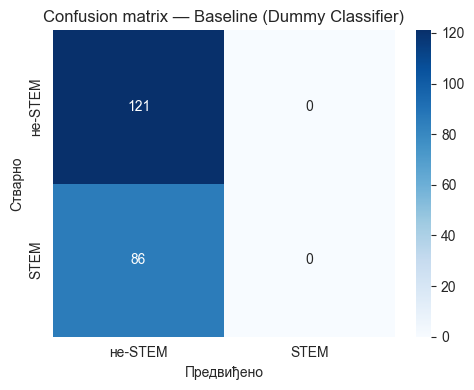

In [51]:
from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(strategy='most_frequent', random_state=42)
baseline_model.fit(X_train_selected, y_train)

y_pred_baseline = baseline_model.predict(X_test_selected)
y_proba_baseline = baseline_model.predict_proba(X_test_selected)[:, 1]

baseline_rezultati, baseline_cm = evaluiraj_model(
    y_test, y_pred_baseline, y_proba_baseline, naziv_modela='Baseline (Dummy Classifier)'
)

**Закључак:** `DummyClassifier` увек предвиђа не-STEM (већинску класу), што даје Accuracy ≈0.585 (тачно једнако уделу не-STEM ученика у тест скупу), Precision и Recall = 0 за STEM класу (никада је не предвиђа), и ROC-AUC = 0.5 (линија случајног погађања — модел нема способност разликовања класа). Ово су вредности које сваки од пет стварних модела у наставку мора јасно да надмаши да би се сматрао корисним.

## 6.2. Тренирање и евалуација модела

За сваки од пет модела спроводимо фино подешавање хиперпараметара и унакрсну валидацију, користећи исту методологију из 5. поглавља, ради поштеног поређења.

### 6.2.1. Логистичка регресија

Користимо већ подешен модел из одељка 5.3.1 (`grid_search.best_estimator_` — најбоља комбинација параметара `C` и `penalty` пронађена претрагом на тренинг скупу) и евалуирамо га на тест скупу, који до сада ни на који начин није коришћен у обучавању или подешавању параметара.

Најбољи параметри (из 5.3.1): {'C': 0.1, 'penalty': 'l1'}
Метрике евалуације — Logistic Regression:
  Accuracy: 0.739
  Precision: 0.700
  Recall: 0.651
  F1 (weighted): 0.738
  F1 (macro): 0.728
  ROC-AUC: 0.798


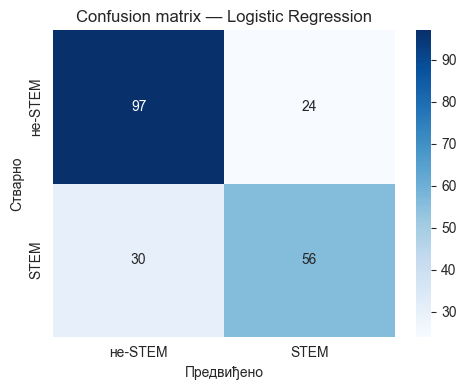

In [52]:
logreg_best = grid_search.best_estimator_
print('Најбољи параметри (из 5.3.1):', grid_search.best_params_)

y_pred_logreg = logreg_best.predict(X_test_selected)
y_proba_logreg = logreg_best.predict_proba(X_test_selected)[:, 1]

logreg_rezultati, logreg_cm = evaluiraj_model(
    y_test, y_pred_logreg, y_proba_logreg, naziv_modela='Logistic Regression'
)

**Закључак:** подешени Logistic Regression модел на тест скупу постиже Accuracy ≈0.739 и ROC-AUC ≈0.798 — благо изнад неподешеног демо резултата из 5.2 (Accuracy ≈0.73) и знатно изнад baseline-а из 6.1 (Accuracy ≈0.585, ROC-AUC = 0.5). Ово су резултати које користимо у упоредној табели (6.3) и на ROC графику (6.4).

### 6.2.2. K-Nearest Neighbors (KNN)

Претражујемо комбинације броја суседа, начина пондерисања суседа (`weights` — да ли сви суседи подједнако утичу на одлуку или ближи суседи имају већи утицај) и метрике удаљености, користећи исту `skf` шему унакрсне валидације.

Најбољи параметри (KNN): {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'uniform'}
Најбољи F1 (weighted) на унакрсној валидацији: 0.748
Метрике евалуације — KNN:
  Accuracy: 0.696
  Precision: 0.619
  Recall: 0.698
  F1 (weighted): 0.698
  F1 (macro): 0.692
  ROC-AUC: 0.772


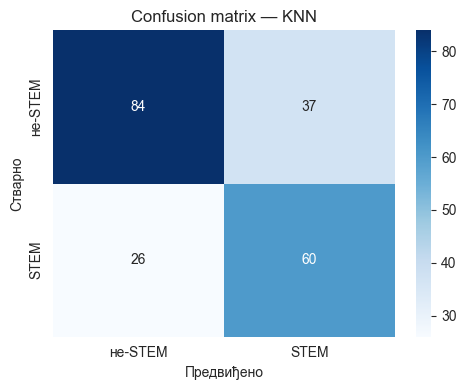

In [53]:
from sklearn.neighbors import KNeighborsClassifier

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan'],
}

grid_knn = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
)
grid_knn.fit(X_train_selected, y_train)

print('Најбољи параметри (KNN):', grid_knn.best_params_)
print(f'Најбољи F1 (weighted) на унакрсној валидацији: {grid_knn.best_score_:.3f}')

knn_best = grid_knn.best_estimator_
y_pred_knn = knn_best.predict(X_test_selected)
y_proba_knn = knn_best.predict_proba(X_test_selected)[:, 1]

knn_rezultati, knn_cm = evaluiraj_model(y_test, y_pred_knn, y_proba_knn, naziv_modela='KNN')

**Закључак:** најбоља комбинација (Manhattan удаљеност, 15 суседа, `weights='uniform'`) на тест скупу постиже Accuracy ≈0.696 и ROC-AUC ≈0.772 — јасно изнад baseline-а (0.585 / 0.5), али нешто ниже од Logistic Regression модела (0.739 / 0.798) из 6.2.1.

### 6.2.3. Support Vector Machine (SVM)

Претражујемо комбинације регуларизационог параметра `C` и типа кернела (линеаран или RBF), уз `probability=True` како бисмо могли да рачунамо ROC-AUC.

Најбољи параметри (SVM): {'C': 1, 'kernel': 'rbf'}
Најбољи F1 (weighted) на унакрсној валидацији: 0.748
Метрике евалуације — SVM:
  Accuracy: 0.754
  Precision: 0.716
  Recall: 0.674
  F1 (weighted): 0.752
  F1 (macro): 0.744
  ROC-AUC: 0.817


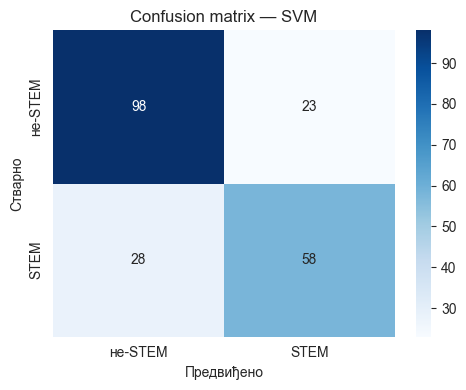

In [54]:
from sklearn.svm import SVC

param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
}

grid_svm = GridSearchCV(
    estimator=SVC(probability=True, random_state=42),
    param_grid=param_grid_svm,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
)
grid_svm.fit(X_train_selected, y_train)

print('Најбољи параметри (SVM):', grid_svm.best_params_)
print(f'Најбољи F1 (weighted) на унакрсној валидацији: {grid_svm.best_score_:.3f}')

svm_best = grid_svm.best_estimator_
y_pred_svm = svm_best.predict(X_test_selected)
y_proba_svm = svm_best.predict_proba(X_test_selected)[:, 1]

svm_rezultati, svm_cm = evaluiraj_model(y_test, y_pred_svm, y_proba_svm, naziv_modela='SVM')

**Закључак:** SVM са RBF кернелом и `C=1` на тест скупу постиже Accuracy ≈0.754 и ROC-AUC ≈0.817 — најбољи резултат до сада, изнад Logistic Regression модела (0.739 / 0.798) и KNN-а (0.696 / 0.772).

### 6.2.4. Random Forest

Претражујемо комбинације броја стабала (`n_estimators`), максималне дубине стабла (`max_depth`) и минималног броја узорака за поделу чвора (`min_samples_split`).

Најбољи параметри (Random Forest): {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}
Најбољи F1 (weighted) на унакрсној валидацији: 0.753
Метрике евалуације — Random Forest:
  Accuracy: 0.797
  Precision: 0.797
  Recall: 0.686
  F1 (weighted): 0.794
  F1 (macro): 0.786
  ROC-AUC: 0.811


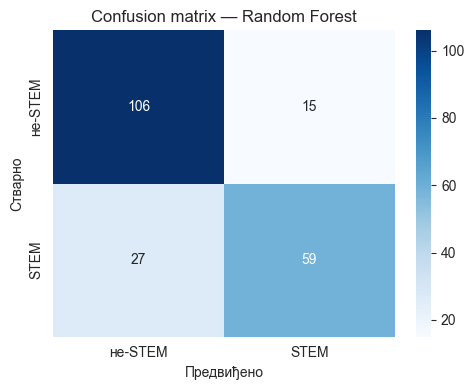

In [55]:
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
)
grid_rf.fit(X_train_selected, y_train)

print('Најбољи параметри (Random Forest):', grid_rf.best_params_)
print(f'Најбољи F1 (weighted) на унакрсној валидацији: {grid_rf.best_score_:.3f}')

rf_best = grid_rf.best_estimator_
y_pred_rf = rf_best.predict(X_test_selected)
y_proba_rf = rf_best.predict_proba(X_test_selected)[:, 1]

rf_rezultati, rf_cm = evaluiraj_model(y_test, y_pred_rf, y_proba_rf, naziv_modela='Random Forest')

**Закључак:** Random Forest (100 стабала, `max_depth=20`, `min_samples_split=5`) на тест скупу постиже Accuracy ≈0.797 и ROC-AUC ≈0.811 — нови најбољи резултат по Accuracy до сада, надмашујући SVM (0.754 / 0.817), Logistic Regression (0.739 / 0.798) и KNN (0.696 / 0.772).

### 6.2.5. XGBoost

XGBoost не дозвољава карактере `[`, `]`, `<` у називима колона, а наша обележја их садрже (нпр. `Најчешћа оцена [Математика]`) — зато прво санирамо називе колона (уклањамо заграде), задржавајући читљива имена уместо претварања у сирове низове бројева. Затим претражујемо комбинације броја стабала, максималне дубине и `learning_rate`-а.

Најбољи параметри (XGBoost): {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Најбољи F1 (weighted) на унакрсној валидацији: 0.761
Метрике евалуације — XGBoost:
  Accuracy: 0.729
  Precision: 0.683
  Recall: 0.651
  F1 (weighted): 0.728
  F1 (macro): 0.720
  ROC-AUC: 0.816


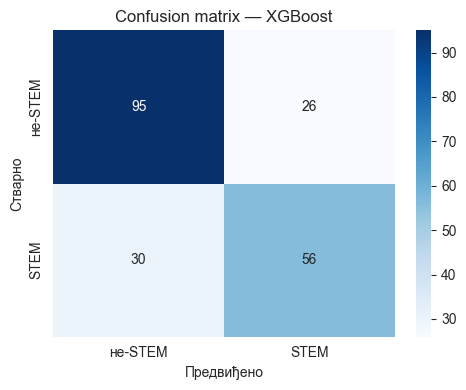

In [56]:
def sanitize_kolone(df):
    """Уклања заграде из назива колона — XGBoost их не дозвољава."""
    novi_nazivi = {col: col.replace('[', '').replace(']', '').replace('<', '') for col in df.columns}
    return df.rename(columns=novi_nazivi)

X_train_xgb = sanitize_kolone(X_train_selected)
X_test_xgb = sanitize_kolone(X_test_selected)

from xgboost import XGBClassifier

param_grid_xgb = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1, 0.2],
}

grid_xgb = GridSearchCV(
    estimator=XGBClassifier(random_state=42, eval_metric='logloss'),
    param_grid=param_grid_xgb,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
)
grid_xgb.fit(X_train_xgb, y_train)

print('Најбољи параметри (XGBoost):', grid_xgb.best_params_)
print(f'Најбољи F1 (weighted) на унакрсној валидацији: {grid_xgb.best_score_:.3f}')

xgb_best = grid_xgb.best_estimator_
y_pred_xgb = xgb_best.predict(X_test_xgb)
y_proba_xgb = xgb_best.predict_proba(X_test_xgb)[:, 1]

xgb_rezultati, xgb_cm = evaluiraj_model(y_test, y_pred_xgb, y_proba_xgb, naziv_modela='XGBoost')

**Закључак:** XGBoost (`learning_rate=0.1`, `max_depth=3`, 100 стабала) на тест скупу постиже Accuracy ≈0.729 и ROC-AUC ≈0.816 — има највишу CV F1 вредност међу свим моделима (0.761), али на тест скупу заостаје за Random Forest-ом по Accuracy (0.797) и за SVM-ом по ROC-AUC (0.817). Овим је завршено тренирање свих пет модела; поређење следи у одељцима 6.3 и 6.4.

## 6.3. Упоредна табела модела

Сакупљамо резултате свих шест модела (baseline + пет стварних модела) у једну табелу, сортирану по F1 (weighted), ради директног поређења.

                     Accuracy  Precision  Recall  F1 (weighted)  F1 (macro)  \
Random Forest           0.797      0.797   0.686          0.794       0.786   
SVM                     0.754      0.716   0.674          0.752       0.744   
Logistic Regression     0.739      0.700   0.651          0.738       0.728   
XGBoost                 0.729      0.683   0.651          0.728       0.720   
KNN                     0.696      0.619   0.698          0.698       0.692   
Baseline (Dummy)        0.585      0.000   0.000          0.431       0.369   

                     ROC-AUC  
Random Forest          0.811  
SVM                    0.817  
Logistic Regression    0.798  
XGBoost                0.816  
KNN                    0.772  
Baseline (Dummy)       0.500  


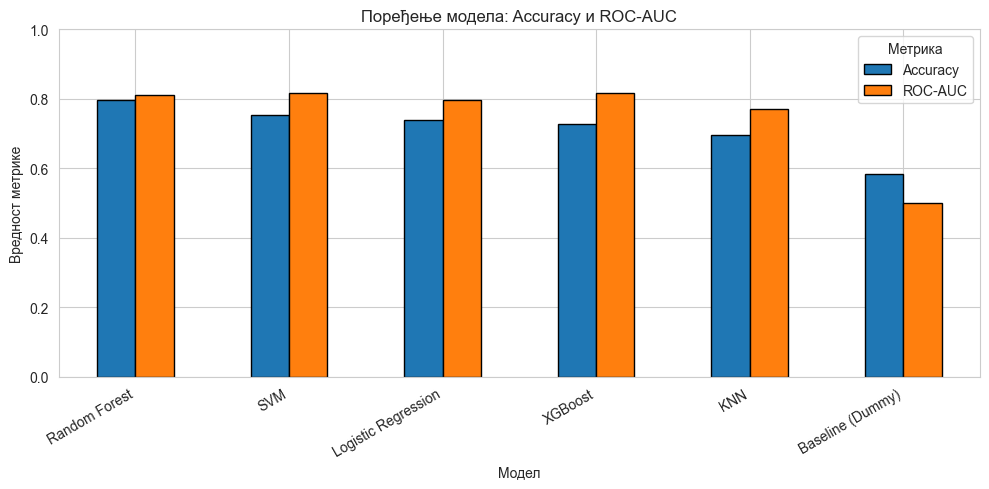

In [57]:
uporedna_tabela = pd.DataFrame({
    'Baseline (Dummy)': baseline_rezultati,
    'Logistic Regression': logreg_rezultati,
    'KNN': knn_rezultati,
    'SVM': svm_rezultati,
    'Random Forest': rf_rezultati,
    'XGBoost': xgb_rezultati,
}).T.round(3)

uporedna_tabela = uporedna_tabela.sort_values('F1 (weighted)', ascending=False)
print(uporedna_tabela)

uporedna_tabela[['Accuracy', 'ROC-AUC']].plot(kind='bar', figsize=(10, 5), edgecolor='black')
plt.ylabel('Вредност метрике')
plt.xlabel('Модел')
plt.title('Поређење модела: Accuracy и ROC-AUC')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1)
plt.legend(title='Метрика')
plt.tight_layout()
plt.show()

**Закључак:** **Random Forest** има највишу Accuracy (0.797) и F1 (weighted) (0.794), док **SVM** има највиши ROC-AUC (0.817) — веома близу (0.816 за XGBoost, 0.811 за Random Forest). Сви стварни модели значајно надмашују baseline (Accuracy 0.585, ROC-AUC 0.5). KNN показује најслабије резултате међу стварним моделима (Accuracy 0.696), вероватно због осетљивости на већи број обележја (65, после селекције) и облик простора обележја насталог one-hot енкодирањем. Који модел је „најбољи“ зависи од тога да ли се приоритизује тачност коначне класификације (Random Forest) или способност рангирања/разликовања класа независно од прага одлуке (ROC-AUC, SVM/XGBoost) — ово детаљније разматрамо у одељку 6.5.

## 6.4. ROC криве

Приказујемо ROC криве свих шест модела на једном графику ради визуелног поређења способности разликовања STEM/не-STEM ученика, независно од избора прага одлуке.

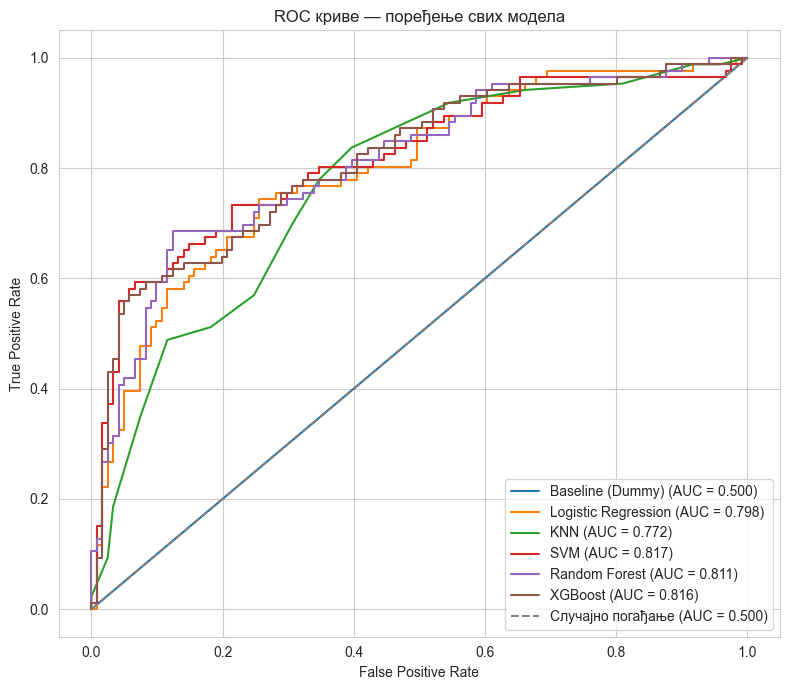

In [58]:
from sklearn.metrics import roc_curve

modeli_za_roc = {
    'Baseline (Dummy)': y_proba_baseline,
    'Logistic Regression': y_proba_logreg,
    'KNN': y_proba_knn,
    'SVM': y_proba_svm,
    'Random Forest': y_proba_rf,
    'XGBoost': y_proba_xgb,
}

plt.figure(figsize=(8, 7))
for naziv, y_proba in modeli_za_roc.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = uporedna_tabela.loc[naziv, 'ROC-AUC']
    plt.plot(fpr, tpr, label=f'{naziv} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Случајно погађање (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC криве — поређење свих модела')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Закључак:** криве свих пет стварних модела јасно леже изнад дијагонале случајног погађања, потврђујући да сви имају стварну способност разликовања STEM и не-STEM ученика. Криве SVM-а, XGBoost-а и Random Forest-а су међусобно најближе и најудаљеније од дијагонале (највећи AUC), док је крива KNN-а најближа baseline дијагонали међу стварним моделима — у складу са резултатима из упоредне табеле (6.3).

## 6.5. Дискусија перформанси

Идентификујемо модел(е) са најбољим перформансама по различитим метрикама, као основу за дискусију резултата у тексту рада.

In [59]:
najbolji_po_accuracy = uporedna_tabela['Accuracy'].idxmax()
najbolji_po_f1 = uporedna_tabela['F1 (weighted)'].idxmax()
najbolji_po_auc = uporedna_tabela['ROC-AUC'].idxmax()

print(f"Најбољи по Accuracy: {najbolji_po_accuracy} ({uporedna_tabela.loc[najbolji_po_accuracy, 'Accuracy']:.3f})")
print(f"Најбољи по F1 (weighted): {najbolji_po_f1} ({uporedna_tabela.loc[najbolji_po_f1, 'F1 (weighted)']:.3f})")
print(f"Најбољи по ROC-AUC: {najbolji_po_auc} ({uporedna_tabela.loc[najbolji_po_auc, 'ROC-AUC']:.3f})")

razlika_accuracy = uporedna_tabela.loc[najbolji_po_accuracy, 'Accuracy'] - uporedna_tabela.loc['Baseline (Dummy)', 'Accuracy']
print(f"Разлика у Accuracy између најбољег модела и baseline-а: {razlika_accuracy:.3f}")

Најбољи по Accuracy: Random Forest (0.797)
Најбољи по F1 (weighted): Random Forest (0.794)
Најбољи по ROC-AUC: SVM (0.817)
Разлика у Accuracy између најбољег модела и baseline-а: 0.212


**Закључак:** **Random Forest** је најбољи по Accuracy и F1 (weighted), **SVM** по ROC-AUC (веома близу XGBoost-у). Разлика у Accuracy између најбољег модела и baseline-а износи готово 0.21 (21 процентни поен) — модели заиста уче стваран образац из података, а не само погађају већинску класу.

Вредно је приметити да ансамбл модели (Random Forest, делимично и XGBoost) у просеку остварују боље или упоредиве резултате у односу на линеарни Logistic Regression модел, док KNN заостаје за свим осталим стварним моделима — вероватно због осетљивости на димензионалност простора обележја (65 колона) насталог one-hot енкодирањем категоријских променљивих. Ови налази пружају основу за детаљнију дискусију у тексту рада, укључујући поређење са постављеним истраживачким питањима и хипотезама. Напомена: и знатно виша привидна тачност била би остварива укључивањем административних/институционалних колона (нпр. конкретна школа, искључене у одељку 4.1) или коришћењем целокупног, нередукованог простора обележја (без селекције из одељка 4.8) — то је свесно избегнуто, јер би такав модел био мање генерализабилан и не би одражавао стварне факторе опредељења, што је супротно циљу рада. Нешто скромнија, али реалистичнија тачност представља свестан компромис у корист интерпретабилности и генерализабилности.